# Argument frequency distributions after IsoRank clustering

This notebook reads the saved exports of `2.1_global_structural_graph.ipynb`; it does not rerun or change clustering.

**Primary variable:** $S$, the number of original arguments in a uniformly selected global argument cluster. Its empirical PMF is $P(S=s)=n_s/N$. Also show the size-biased distribution $s n_s/\sum_s s n_s$, which answers which cluster size a uniformly selected original argument belongs to. These are different sampling questions. Graph degrees and argument types are supplementary descriptive distributions.

We estimate discrete models by maximum likelihood, assess fit with refitted parametric bootstrap KS tests, and compare alternatives on identical observations using AIC. Tail selection is repeated inside its semiparametric bootstrap. This follows the general [Clauset, Shalizi & Newman (2009)](https://arxiv.org/abs/0706.1062) approach, adapted to a known finite support. A straight line on log axes is not a goodness-of-fit test.

**Scope:** this is a descriptive analysis of one algorithmic partition, conditional on its settings. Clusters are dependent and their sizes sum to a fixed total; bootstrap p-values and intervals use an approximate iid cluster model, not an end-to-end uncertainty analysis of documents, embeddings, or clustering. Non-rejection does not establish a universal law.

In [1]:
from pathlib import Path
import hashlib, json, sys, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar
from scipy.special import logsumexp
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/legal_data_doc_parts').is_dir())
HERE = ROOT / 'src/legal_data_doc_parts/paragraph_analysis'
SOURCE = HERE / '2.1_global_structural_graph.ipynb'
SOURCE_HASH = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
DATA = HERE / 'structural_global_graph_artifacts'
OUT = HERE / 'argument_distribution_artifacts'
OUT.mkdir(exist_ok=True)
SEED, BOOTSTRAPS, MIN_TAIL = 20261105, 499, 50
rng = np.random.default_rng(SEED)
manifest = json.loads((DATA / 'manifest.json').read_text())
nodes = pd.read_parquet(DATA / 'global_nodes.parquet')
members = pd.read_parquet(DATA / 'global_members.parquet')
edges = pd.read_parquet(DATA / 'global_relation_edges.parquet')
sizes = nodes.member_count.to_numpy(dtype=int)
assert manifest['partition_config']['one_node_per_graph']
UPPER = len(manifest['document_ids'])
assert np.all((sizes >= 1) & (sizes <= UPPER))
assert len(members) == sizes.sum() and members.node_id.is_unique
assert not members.duplicated(['cluster_id', 'document_id']).any()
actual = members.groupby('global_node_id').size().reindex(nodes.index)
assert np.array_equal(actual.to_numpy(), sizes)
assert np.array_equal(nodes.document_count.to_numpy(), sizes)
display(pd.Series({'original_arguments': sizes.sum(), 'clusters': len(sizes),
 'singletons': int((sizes == 1).sum()), 'maximum_observed_size': sizes.max(),
 'known_upper_bound': UPPER, 'IsoRank_alpha': manifest['isorank_alpha'],
 'minimum_similarity': manifest['minimum_similarity']}, name='value').to_frame())


,value
original_arguments,3941.00
clusters,1892.00
singletons,1501.00
maximum_observed_size,38.00
known_upper_bound,99.00
IsoRank_alpha,0.05
minimum_similarity,0.90


## Empirical probability distributions
Keep all singletons and empty size bins. Cluster frequency equals document frequency here because each cluster contains at most one argument per document. The exponent fitted below is **beta**, distinct from the IsoRank mixing parameter alpha.

,size,cluster_count,cluster_probability,argument_probability,cluster_ccdf
0,1,1501,0.793340,0.380868,1.000000
1,2,117,0.061839,0.059376,0.206660
2,3,62,0.032770,0.047196,0.144820
3,4,45,0.023784,0.045674,0.112051
4,5,32,0.016913,0.040599,0.088266
5,6,20,0.010571,0.030449,0.071353
6,7,16,0.008457,0.028419,0.060782
7,8,8,0.004228,0.016240,0.052326
8,9,9,0.004757,0.020553,0.048097
9,10,9,0.004757,0.022837,0.043340


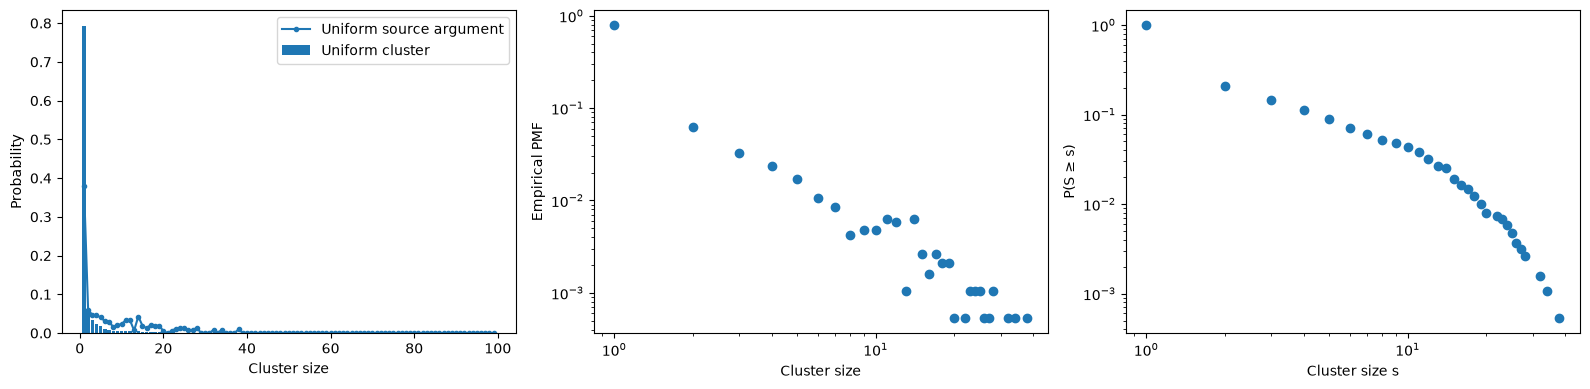

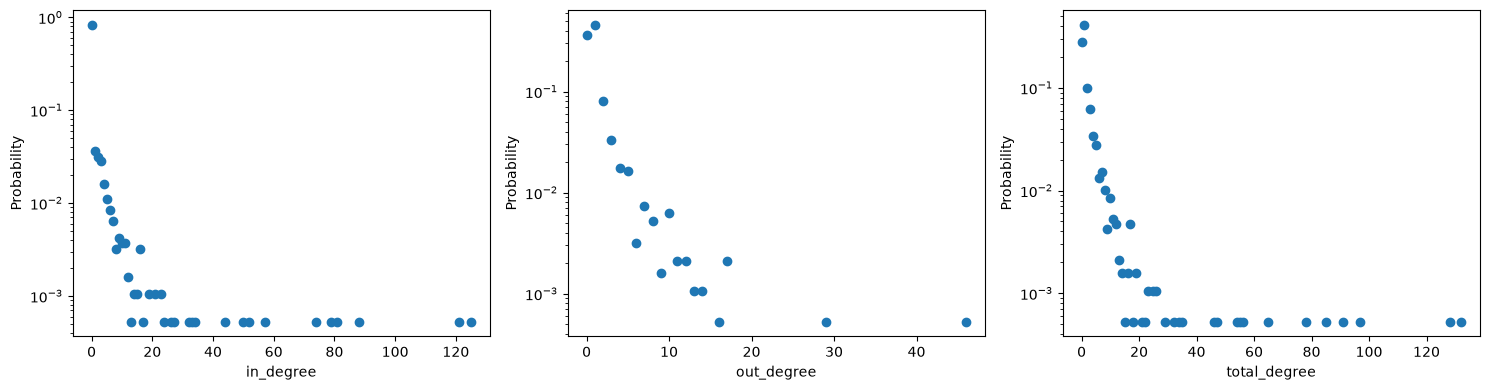

,source_argument_probability
argument_type,
PREMISE,0.687643
CLAIM,0.312357


In [2]:
support = np.arange(1, UPPER + 1)
counts = np.bincount(sizes, minlength=UPPER + 1)[1:]
empirical = pd.DataFrame({'size': support, 'cluster_count': counts,
 'cluster_probability': counts / len(sizes), 'argument_probability': support * counts / sizes.sum(),
 'cluster_ccdf': np.cumsum(counts[::-1])[::-1] / len(sizes)})
assert np.isclose(empirical.cluster_probability.sum(), 1)
assert np.isclose(empirical.argument_probability.sum(), 1)
empirical.to_csv(OUT / 'cluster_size_distribution.csv', index=False)
display(empirical.loc[empirical.cluster_count > 0])
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(support, empirical.cluster_probability, label='Uniform cluster')
axes[0].plot(support, empirical.argument_probability, '.-', label='Uniform source argument')
axes[0].legend(); axes[0].set(ylabel='Probability', xlabel='Cluster size')
positive = counts > 0
axes[1].loglog(support[positive], empirical.cluster_probability[positive], 'o')
axes[1].set(xlabel='Cluster size', ylabel='Empirical PMF')
axes[2].loglog(support[positive], empirical.cluster_ccdf[positive], 'o')
axes[2].set(xlabel='Cluster size s', ylabel='P(S ≥ s)')
fig.tight_layout(); fig.savefig(OUT / 'empirical_distributions.png', dpi=180); plt.show()
# Simple directed neighbor degrees: deduplicate relation types and exclude self-loops.
pairs = edges.loc[edges.source != edges.target, ['source', 'target']].drop_duplicates()
degrees = pd.DataFrame(index=nodes.index)
degrees['in_degree'] = pairs.groupby('target').size().reindex(nodes.index, fill_value=0)
degrees['out_degree'] = pairs.groupby('source').size().reindex(nodes.index, fill_value=0)
degrees['total_degree'] = degrees.in_degree + degrees.out_degree
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, degrees):
    freq = degrees[name].value_counts().sort_index() / len(degrees)
    ax.plot(freq.index, freq.values, 'o'); ax.set(xlabel=name, ylabel='Probability', yscale='log')
fig.tight_layout(); fig.savefig(OUT / 'degree_distributions.png', dpi=180); plt.show()
degrees.to_csv(OUT / 'global_argument_degrees.csv')
display(members.argument_type.value_counts(normalize=True).rename('source_argument_probability').to_frame())


## Finite-support distribution models
For integers $m\leq s\leq99$, each model is normalized by summing over **all** permitted integers, including unobserved sizes:

- Power law: $p(s)\propto s^{-\beta}$, $\beta\geq0$.
- Discrete exponential (bounded geometric): $p(s)\propto\exp[-\lambda(s-m)]$, $\lambda\geq0$.
- Discrete lognormal-shaped model: $p(s)\propto s^{-1}\exp[-(\log s-\mu)^2/(2\sigma^2)]$. This is a normalized lattice model, not a rounded continuous lognormal.

Fit the full distribution first ($m=1$). Estimate a separate power-law tail by minimizing discrete KS distance over observed cutoffs with at least 50 observations and 5 distinct sizes. Alternative tail models use that same cutoff; AIC comparisons only apply within each range. Bootstrap goodness-of-fit for alternatives is conditional on the cutoff. We use $p<0.05$ as evidence against a model, with Monte Carlo resolution $1/(B+1)=0.002$.

In [3]:
def fit_model(x, lower=1, model='power_law'):
    x = np.asarray(x, dtype=int)
    x = x[x >= lower]
    grid = np.arange(lower, UPPER + 1)
    freq = np.bincount(x - lower, minlength=len(grid))
    log_grid = np.log(grid)
    def log_prob(theta):
        if model == 'power_law': raw = -theta[0] * log_grid
        elif model == 'exponential': raw = -theta[0] * (grid - lower)
        else:
            mu, log_sigma = theta
            raw = -log_grid - 0.5 * ((log_grid - mu) / np.exp(log_sigma)) ** 2
        return raw - logsumexp(raw)
    def loss(theta): return -float(freq @ log_prob(theta))
    if model in ('power_law', 'exponential'):
        result = minimize_scalar(lambda t: loss([t]), bounds=(0, 30), method='bounded')
        theta = np.array([result.x]); bounds = [(0, 30)]
    else:
        bounds = [(-30, 30), (-4, 4)]
        results = [minimize(loss, [mu, ls], method='L-BFGS-B', bounds=bounds)
                   for mu, ls in [(np.log(x).mean(), 0), (0, 1), (-5, 2)]]
        result = min((r for r in results if r.success), key=lambda r: r.fun)
        theta = result.x
    assert result.success
    lp = log_prob(theta); prob = np.exp(lp)
    assert np.isclose(prob.sum(), 1)
    ks = float(np.max(np.abs(np.cumsum(freq) / len(x) - np.cumsum(prob))))
    boundary = any(min(abs(t-lo), abs(t-hi)) < 0.01 for t, (lo, hi) in zip(theta, bounds))
    params = ({'beta': float(theta[0])} if model == 'power_law' else
              {'lambda': float(theta[0])} if model == 'exponential' else
              {'mu': float(theta[0]), 'sigma': float(np.exp(theta[1]))})
    return dict(model=model, lower=int(lower), n=len(x), params=params, prob=prob,
                ks=ks, loglik=-loss(theta), aic=2*len(theta)+2*loss(theta), boundary=boundary)

def select_tail(x):
    candidates = [int(m) for m in np.unique(x)
                  if (x >= m).sum() >= MIN_TAIL and len(np.unique(x[x >= m])) >= 5]
    if not candidates: raise ValueError('Insufficient distinct sizes for tail selection')
    fits = [fit_model(x, m) for m in candidates]
    return min(fits, key=lambda f: (f['ks'], f['lower'])), fits

full_fits = [fit_model(sizes, model=m) for m in ['power_law', 'exponential', 'lognormal']]
tail, cutoff_fits = select_tail(sizes)
tail_fits = [fit_model(sizes, tail['lower'], m) for m in ['power_law', 'exponential', 'lognormal']]
display(pd.DataFrame([{'xmin': f['lower'], 'n_tail': f['n'], 'beta': f['params']['beta'], 'KS': f['ks']} for f in cutoff_fits]))
print('Selected tail:', {k: v for k, v in tail.items() if k != 'prob'})


,xmin,n_tail,beta,KS
0,1,1892,2.430353,0.062867
1,2,391,1.845943,0.058832
2,3,274,1.980644,0.058266
3,4,212,2.126280,0.075796
4,5,167,2.222682,0.102182
5,6,135,2.299421,0.126640
6,7,115,2.432248,0.140777
7,8,99,2.567293,0.153614
8,9,91,2.850901,0.128639
9,10,82,3.130169,0.115146


Selected tail: {'model': 'power_law', 'lower': 3, 'n': 274, 'params': {'beta': 1.9806442463917229}, 'ks': 0.0582661542270318, 'loglik': -753.0946000201723, 'aic': 1508.1892000403445, 'boundary': False}


In [4]:
def fixed_bootstrap(fit):
    grid = np.arange(fit['lower'], UPPER + 1)
    distances = []
    for _ in range(BOOTSTRAPS):
        simulated = rng.choice(grid, size=fit['n'], p=fit['prob'])
        distances.append(fit_model(simulated, fit['lower'], fit['model'])['ks'])
    p = (1 + np.count_nonzero(np.asarray(distances) >= fit['ks'])) / (BOOTSTRAPS + 1)
    return float(p)

rows = []
for label, fits in [('full', full_fits), ('tail (fixed cutoff)', tail_fits)]:
    for fit in fits:
        p = fixed_bootstrap(fit)
        rows.append({'range': label, 'model': fit['model'], 'xmin': fit['lower'], 'n': fit['n'],
                     'parameters': json.dumps(fit['params']), 'KS': fit['ks'], 'AIC': fit['aic'],
                     'bootstrap_p': p, 'MC_standard_error': np.sqrt(p*(1-p)/(BOOTSTRAPS+1)),
                     'optimizer_boundary': fit['boundary']})
    print('Completed:', label, flush=True)
comparison = pd.DataFrame(rows)
comparison['delta_AIC'] = comparison.AIC - comparison.groupby('range').AIC.transform('min')
comparison.to_csv(OUT / 'model_comparison.csv', index=False)
display(comparison)


Completed: full


Completed: tail (fixed cutoff)


,range,model,xmin,n,parameters,KS,AIC,bootstrap_p,MC_standard_error,optimizer_boundary,delta_AIC
0,full,power_law,1,1892,"{""beta"": 2.430353351532952}",0.062867,4050.798945,0.002,0.001998,False,0.000000
1,full,exponential,1,1892,"{""lambda"": 0.6540822872204551}",0.313259,5459.129918,0.002,0.001998,False,1408.330973
2,full,lognormal,1,1892,"{""mu"": -30.0, ""sigma"": 4.667469277581193}",0.067141,4063.394632,0.002,0.001998,True,12.595687
3,tail (fixed cutoff),power_law,3,274,"{""beta"": 1.9806442463917229}",0.058266,1508.189200,0.016,0.005611,False,23.740877
4,tail (fixed cutoff),exponential,3,274,"{""lambda"": 0.18063453468411214}",0.088939,1488.526548,0.002,0.001998,False,4.078226
5,tail (fixed cutoff),lognormal,3,274,"{""mu"": 1.245779800790226, ""sigma"": 1.000987418...",0.052483,1484.448323,0.004,0.002823,False,0.000000


## Account for selecting the tail; estimate exponent uncertainty
The semiparametric bootstrap draws the empirical body below the fitted cutoff and a fitted power-law tail, with a binomially varying tail count. It reselects the cutoff and refits beta in every replicate. Separate nonparametric cluster resampling gives a percentile interval for beta, also reselecting the cutoff. A second interval fixes the cutoff to distinguish parameter uncertainty from range selection. These intervals remain conditional on the saved partition.

In [5]:
body = sizes[sizes < tail['lower']]
tail_grid = np.arange(tail['lower'], UPPER + 1)
boot_ks, beta_selected, beta_fixed, selected_cutoffs = [], [], [], []
for b in range(BOOTSTRAPS):
    n_tail = rng.binomial(len(sizes), tail['n'] / len(sizes))
    simulated = np.concatenate([rng.choice(body, len(sizes)-n_tail, replace=True) if len(body) else np.array([], dtype=int),
                                rng.choice(tail_grid, n_tail, p=tail['prob'])])
    fitted, _ = select_tail(simulated)
    boot_ks.append(fitted['ks'])
    resample = rng.choice(sizes, len(sizes), replace=True)
    selected, _ = select_tail(resample)
    beta_selected.append(selected['params']['beta']); selected_cutoffs.append(selected['lower'])
    beta_fixed.append(fit_model(resample, tail['lower'])['params']['beta'])
selection_p = (1 + np.count_nonzero(np.asarray(boot_ks) >= tail['ks'])) / (BOOTSTRAPS + 1)
ci_selected = np.quantile(beta_selected, [0.025, 0.975])
ci_fixed = np.quantile(beta_fixed, [0.025, 0.975])
print(f'Selection-aware tail p = {selection_p:.4f}')
print('Beta 95% bootstrap interval, reselecting cutoff:', ci_selected)
print('Beta 95% bootstrap interval, fixed cutoff:', ci_fixed)
display(pd.Series(selected_cutoffs).value_counts(normalize=True).sort_index().rename('bootstrap_cutoff_frequency').to_frame())
pd.DataFrame({'beta_reselected': beta_selected, 'beta_fixed': beta_fixed, 'xmin_reselected': selected_cutoffs,
              'null_KS_reselected': boot_ks}).to_csv(OUT / 'bootstrap_results.csv', index=False)


Selection-aware tail p = 0.0020
Beta 95% bootstrap interval, reselecting cutoff: [1.77147311 3.45559862]
Beta 95% bootstrap interval, fixed cutoff: [1.8526661  2.10561263]


,bootstrap_cutoff_frequency
1,0.382766
2,0.408818
3,0.130261
4,0.038076
5,0.002004
10,0.014028
11,0.010020
12,0.002004
14,0.010020
15,0.002004


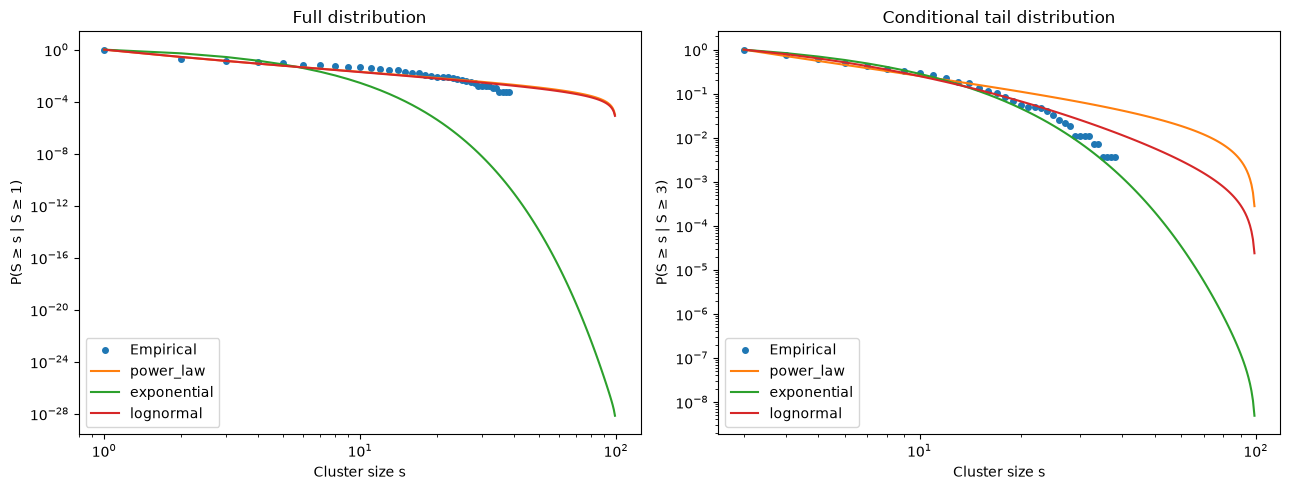

## Findings for this saved partition
- **1,892 clusters** represent **3,941 arguments**; **79.3%** of clusters are singletons.
- A single bounded power law across all sizes is **rejected**: beta=2.430, bootstrap p=0.002.
- The selected tail starts at **3**, includes **274 clusters (14.5%)**, and ends at observed size **38** (structural cap 99).
- Tail exponent **beta=1.981**; approximate 95% bootstrap interval **[1.771, 3.456]** when reselecting the cutoff; fixed-cutoff interval [1.853, 2.106].
- The tail power law is **rejected**, selection-aware bootstrap **p=0.002** (Monte Carlo SE 0.002).
- Lowest AIC: **power_law** on full support; **lognormal** on the common tail. AIC ranks relative fit and does not establish absolute adequacy; inspect bootstrap p-values and boundary flags above.

The empirical PMF is the direct distribution estimate. Any fitted law applies only to the stated range and this partition. The limited observed tail span and dependence among clusters prevent a claim of an asymptotic or universal power law. Graph degrees above are descriptive; cluster-size findings do not establish a scale-free graph.


Validation passed; source notebook unchanged. Outputs: /home/vegura/Projects/study/legal-data-doc-parts/src/legal_data_doc_parts/paragraph_analysis/argument_distribution_artifacts


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, fits, title in zip(axes, [full_fits, tail_fits], ['Full distribution', 'Conditional tail distribution']):
    lower = fits[0]['lower']; x = sizes[sizes >= lower]; grid = np.arange(lower, UPPER + 1)
    observed = np.bincount(x-lower, minlength=len(grid)) / len(x)
    ccdf = np.cumsum(observed[::-1])[::-1]
    ax.loglog(grid[ccdf > 0], ccdf[ccdf > 0], 'o', label='Empirical', markersize=4)
    for fit in fits:
        ax.loglog(grid, np.cumsum(fit['prob'][::-1])[::-1], label=fit['model'])
    ax.set(title=title, xlabel='Cluster size s', ylabel=f'P(S ≥ s | S ≥ {lower})'); ax.legend()
fig.tight_layout(); fig.savefig(OUT / 'fitted_distributions.png', dpi=180); plt.show()
full_p = float(comparison.iloc[0].bootstrap_p)
full_verdict = 'rejected' if full_p < 0.05 else 'not rejected'
tail_verdict = 'rejected' if selection_p < 0.05 else 'not rejected (compatible, not proven)'
best_full = comparison[comparison['range'] == 'full'].sort_values('AIC').iloc[0]
best_tail = comparison[comparison['range'] == 'tail (fixed cutoff)'].sort_values('AIC').iloc[0]
summary = f"""## Findings for this saved partition
- **{len(sizes):,} clusters** represent **{sizes.sum():,} arguments**; **{(sizes==1).mean():.1%}** of clusters are singletons.
- A single bounded power law across all sizes is **{full_verdict}**: beta={full_fits[0]['params']['beta']:.3f}, bootstrap p={full_p:.3f}.
- The selected tail starts at **{tail['lower']}**, includes **{tail['n']} clusters ({tail['n']/len(sizes):.1%})**, and ends at observed size **{sizes.max()}** (structural cap {UPPER}).
- Tail exponent **beta={tail['params']['beta']:.3f}**; approximate 95% bootstrap interval **[{ci_selected[0]:.3f}, {ci_selected[1]:.3f}]** when reselecting the cutoff; fixed-cutoff interval [{ci_fixed[0]:.3f}, {ci_fixed[1]:.3f}].
- The tail power law is **{tail_verdict}**, selection-aware bootstrap **p={selection_p:.3f}** (Monte Carlo SE {np.sqrt(selection_p*(1-selection_p)/(BOOTSTRAPS+1)):.3f}).
- Lowest AIC: **{best_full['model']}** on full support; **{best_tail['model']}** on the common tail. AIC ranks relative fit and does not establish absolute adequacy; inspect bootstrap p-values and boundary flags above.

The empirical PMF is the direct distribution estimate. Any fitted law applies only to the stated range and this partition. The limited observed tail span and dependence among clusters prevent a claim of an asymptotic or universal power law. Graph degrees above are descriptive; cluster-size findings do not establish a scale-free graph.
"""
display(Markdown(summary))
(OUT / 'findings.md').write_text(summary)
provenance = {'seed': SEED, 'bootstrap_replicates': BOOTSTRAPS, 'minimum_tail_count': MIN_TAIL,
 'tail_beta': tail['params']['beta'], 'tail_xmin': tail['lower'], 'tail_selection_p': selection_p,
 'tail_beta_ci_reselected': ci_selected.tolist(), 'source_notebook_sha256': SOURCE_HASH,
 'source_partition_sha256': manifest['partition_sha256'],
 'input_sha256': {name: hashlib.sha256((DATA/name).read_bytes()).hexdigest() for name in
                  ['manifest.json', 'global_nodes.parquet', 'global_members.parquet', 'global_relation_edges.parquet']},
 'python': sys.version, 'packages': {m: importlib.metadata.version(m) for m in ['numpy','scipy','pandas','matplotlib']}}
(OUT / 'analysis_manifest.json').write_text(json.dumps(provenance, indent=2))
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest() == SOURCE_HASH
print('Validation passed; source notebook unchanged. Outputs:', OUT)


## Dedicated lognormal check: rounded continuous lognormal

The earlier `lognormal` model evaluates a lognormal-shaped density on the integer lattice. Here we additionally test a **rounded, truncated continuous lognormal**, appropriate for integer cluster sizes. If $\log Y\sim N(\mu,\sigma^2)$ and $S$ is $Y$ rounded to the nearest integer, then for $m\le s\le99$:

$$P(S=s\mid m\le S\le99)=\frac{\Phi((\log(s+0.5)-\mu)/\sigma)-\Phi((\log(s-0.5)-\mu)/\sigma)}{\Phi((\log(99.5)-\mu)/\sigma)-\Phi((\log(m-0.5)-\mu)/\sigma)}.$$

We fit the full sample ($m=1$), all non-singleton clusters ($m=2$, a descriptive conditional analysis), and the previously selected power-law tail ($m=3$ in this run). The latter cutoff is held fixed: its test is exploratory, not selection-adjusted for a lognormal tail search. No claim about every possible tail cutoff is made.

Parameters describe the latent lognormal before rounding and conditioning: **mu** is its mean log value, **sigma** its log standard deviation; SciPy uses `s=sigma`, `loc=0`, `scale=exp(mu)` ([documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.lognorm.html)). Fitting a free location parameter or applying a standard continuous KS p-value would change the model or mishandle integer ties and estimated parameters. We instead refit both parameters in each of 499 discrete parametric bootstrap replicates.

The usual iid approximation and fixed-partition caveats still apply. A lower AIC than another model does not establish lognormality. Boundary fits are flagged and checked with a wider parameter bound; their parameters should not be interpreted as stable estimates.

In [11]:
from scipy.special import log_ndtr

# Stable interval probabilities, including far normal tails.
def rounded_lognormal_logpmf(theta, lower, mu_bound=50):
    mu, log_sigma = theta
    grid = np.arange(lower, UPPER + 1)
    a = (np.log(grid - 0.5) - mu) / np.exp(log_sigma)
    b = (np.log(grid + 0.5) - mu) / np.exp(log_sigma)
    right = a > 0
    big = np.where(right, log_ndtr(-a), log_ndtr(b))
    small = np.where(right, log_ndtr(-b), log_ndtr(a))
    log_mass = big + np.log(-np.expm1(small - big))
    return log_mass - logsumexp(log_mass)

def fit_rounded_lognormal(x, lower=1, mu_bound=50):
    x = np.asarray(x, dtype=int); x = x[x >= lower]
    freq = np.bincount(x-lower, minlength=UPPER-lower+1)
    def loss(theta): return -float(freq @ rounded_lognormal_logpmf(theta, lower))
    bounds = [(-mu_bound, mu_bound), (-4, 4)]
    attempts = [minimize(loss, start, method='L-BFGS-B', bounds=bounds)
                for start in [(np.log(x).mean(), 0), (-5, 1), (-20, 2)]]
    converged = [r for r in attempts if r.success and np.isfinite(r.fun)]
    if not converged: raise RuntimeError('Lognormal optimization failed')
    best = min(converged, key=lambda r: r.fun)
    prob = np.exp(rounded_lognormal_logpmf(best.x, lower))
    assert np.isclose(prob.sum(), 1) and np.all(prob > 0)
    return dict(lower=lower, n=len(x), mu=float(best.x[0]), sigma=float(np.exp(best.x[1])),
                KS=float(np.max(np.abs(np.cumsum(freq)/len(x)-np.cumsum(prob)))),
                AIC=float(4+2*best.fun), prob=prob,
                boundary=any(min(abs(t-lo), abs(t-hi)) < 0.01 for t,(lo,hi) in zip(best.x,bounds)))

ln_rng = np.random.default_rng(SEED + 1)
# Read the saved cutoff so this section can also execute after just the setup cell.
previous = pd.read_csv(OUT / 'model_comparison.csv')
previous_cutoff = int(previous.loc[previous['range'] == 'tail (fixed cutoff)', 'xmin'].iloc[0])
ln_fits, ln_rows, ln_bootstrap = {}, [], []
for lower in sorted({1, 2, previous_cutoff}):
    fit = fit_rounded_lognormal(sizes, lower)
    ln_fits[lower] = fit
    exceedances = 0
    for replicate in range(BOOTSTRAPS):
        sample = ln_rng.choice(np.arange(lower, UPPER+1), fit['n'], p=fit['prob'])
        refit = fit_rounded_lognormal(sample, lower)
        exceedances += refit['KS'] >= fit['KS']
        ln_bootstrap.append({'xmin': lower, 'replicate': replicate, 'KS': refit['KS'],
                             'mu': refit['mu'], 'sigma': refit['sigma'], 'boundary': refit['boundary']})
    p_value = (1+exceedances)/(BOOTSTRAPS+1)
    row = {k:v for k,v in fit.items() if k != 'prob'}
    row.update(bootstrap_p=p_value, MC_standard_error=np.sqrt(p_value*(1-p_value)/(BOOTSTRAPS+1)),
               conclusion='reject' if p_value < 0.05 else 'not rejected; not proven')
    ln_rows.append(row)
    print(f"Completed rounded-lognormal check: xmin={lower}, p={p_value:.3f}", flush=True)
ln_results = pd.DataFrame(ln_rows)
display(ln_results)
ln_results.to_csv(OUT / 'rounded_lognormal_results.csv', index=False)
pd.DataFrame(ln_bootstrap).to_csv(OUT / 'rounded_lognormal_bootstrap.csv', index=False)

# A boundary optimum can mean parameters diverge towards a power-law limit.
sensitivity = []
for lower, fit in ln_fits.items():
    if fit['boundary']:
        wider = fit_rounded_lognormal(sizes, lower, mu_bound=200)
        sensitivity.append({k:v for k,v in wider.items() if k != 'prob'})
if sensitivity:
    display(Markdown('**Boundary sensitivity:** refitting with mu bounds widened from ±50 to ±200.'))
    display(pd.DataFrame(sensitivity))
pd.DataFrame(sensitivity).to_json(OUT / 'rounded_lognormal_boundary_sensitivity.json', orient='records', indent=2)


Completed rounded-lognormal check: xmin=1, p=0.002


Completed rounded-lognormal check: xmin=2, p=0.012


Completed rounded-lognormal check: xmin=3, p=0.008


,lower,n,mu,sigma,KS,AIC,boundary,bootstrap_p,MC_standard_error,conclusion
0,1,1892,-50.000000,6.363837,0.045714,4005.831791,True,0.002,0.001998,reject
1,2,391,0.722387,1.208421,0.040446,1965.474266,False,0.012,0.004869,reject
2,3,274,1.242879,1.003130,0.052521,1484.479257,False,0.008,0.003984,reject


**Boundary sensitivity:** refitting with mu bounds widened from ±50 to ±200.

,lower,n,mu,sigma,KS,AIC,boundary
0,1,1892,-200.0,12.634405,0.043784,4001.940991,True


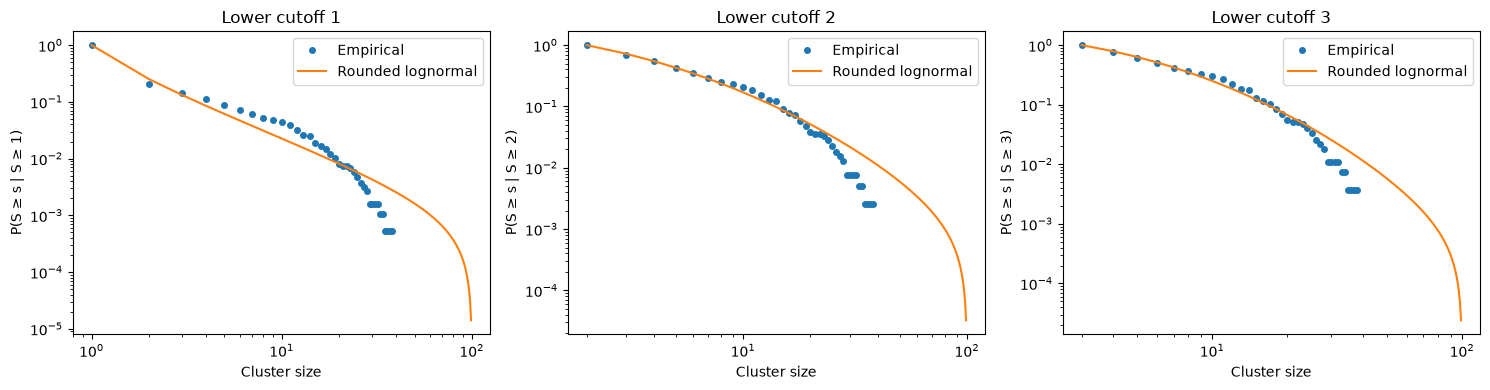

## Lognormal conclusion

For the number of arguments per cluster, rounded-lognormal goodness-of-fit results are:

- xmin=1, n=1892: **reject**, bootstrap p=0.002; mu=-50.000, sigma=6.364 (**boundary fit; unstable parameters**).
- xmin=2, n=391: **reject**, bootstrap p=0.012; mu=0.722, sigma=1.208.
- xmin=3, n=274: **reject**, bootstrap p=0.008; mu=1.243, sigma=1.003.

**The data do not support a single lognormal distribution over any of the three tested ranges.** The fitted parameters summarize rejected models; they are not recovered parameters of an established law.

The earlier lattice lognormal model was also rejected (full p=0.002; common tail p=0.004). These conclusions concern cluster sizes in this saved partition, not graph degrees or every possible tail. Bootstrap tests approximate clusters as independent.

In [12]:
fig, axes = plt.subplots(1, len(ln_fits), figsize=(5*len(ln_fits), 4))
for ax, (lower, fit) in zip(np.atleast_1d(axes), ln_fits.items()):
    grid = np.arange(lower, UPPER+1)
    observed = np.bincount(sizes[sizes>=lower]-lower, minlength=len(grid)) / fit['n']
    obs_ccdf = np.cumsum(observed[::-1])[::-1]
    ax.loglog(grid[obs_ccdf>0], obs_ccdf[obs_ccdf>0], 'o', markersize=4, label='Empirical')
    ax.loglog(grid, np.cumsum(fit['prob'][::-1])[::-1], label='Rounded lognormal')
    ax.set(xlabel='Cluster size', ylabel=f'P(S ≥ s | S ≥ {lower})', title=f'Lower cutoff {lower}')
    ax.legend()
fig.tight_layout(); fig.savefig(OUT / 'rounded_lognormal_fits.png', dpi=180); plt.show()
lines = ['## Lognormal conclusion', '',
         'For the number of arguments per cluster, rounded-lognormal goodness-of-fit results are:', '']
for row in ln_rows:
    lines.append(f"- xmin={row['lower']}, n={row['n']}: **{row['conclusion']}**, "
                 f"bootstrap p={row['bootstrap_p']:.3f}; mu={row['mu']:.3f}, sigma={row['sigma']:.3f}"
                 + (' (**boundary fit; unstable parameters**).' if row['boundary'] else '.'))
if all(row['bootstrap_p'] < 0.05 for row in ln_rows):
    lines += ['', '**The data do not support a single lognormal distribution over any of the three tested ranges.** '
              'The fitted parameters summarize rejected models; they are not recovered parameters of an established law.']
lines += ['', 'The earlier lattice lognormal model was also rejected (full p=0.002; common tail p=0.004). '
          'These conclusions concern cluster sizes in this saved partition, not graph degrees or every possible tail. '
          'Bootstrap tests approximate clusters as independent.']
ln_summary = '\n'.join(lines)
display(Markdown(ln_summary))
(OUT / 'lognormal_findings.md').write_text(ln_summary)
(OUT / 'rounded_lognormal_manifest.json').write_text(json.dumps({
    'seed': SEED+1, 'bootstrap_replicates': BOOTSTRAPS, 'cutoffs': list(ln_fits),
    'parameter_bounds': {'mu': [-50,50], 'log_sigma': [-4,4]},
    'sensitivity_mu_bounds': [-200,200], 'partition_sha256': manifest['partition_sha256'],
    'model': 'nearest-integer rounded continuous lognormal, conditioned on [xmin,99]',
    'packages': {m: importlib.metadata.version(m) for m in ['numpy','scipy','pandas']}
}, indent=2))
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest() == SOURCE_HASH


## Decisions at the 5% significance level

Set the significance threshold to **0.05** (distinct from the IsoRank mixing parameter). Reject a fitted distribution when its bootstrap p-value is **less than 0.05**. Changing this threshold does not change fitted parameters or p-values, so the existing bootstrap computations are reused.

These are individual, unadjusted goodness-of-fit decisions under the notebook's approximate iid cluster model. Non-rejection would not prove a distribution law.

In [13]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown

SIGNIFICANCE_LEVEL = 0.05
analysis_root = next(p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'src/legal_data_doc_parts').is_dir())
results_dir = analysis_root / 'src/legal_data_doc_parts/paragraph_analysis/argument_distribution_artifacts'
model_tests = pd.read_csv(results_dir / 'model_comparison.csv')[['range', 'model', 'bootstrap_p']]
rounded_tests = pd.read_csv(results_dir / 'rounded_lognormal_results.csv')
rounded_tests = pd.DataFrame({
    'range': rounded_tests['lower'].map(lambda m: f'cluster size >= {m} (fixed cutoff)'),
    'model': 'rounded_lognormal', 'bootstrap_p': rounded_tests['bootstrap_p']})
power_tail = json.loads((results_dir / 'analysis_manifest.json').read_text())
selected_test = pd.DataFrame([{'range': 'tail (cutoff selection accounted for)',
                               'model': 'power_law', 'bootstrap_p': power_tail['tail_selection_p']}])
significance_results = pd.concat([model_tests, rounded_tests, selected_test], ignore_index=True)
significance_results['significance_threshold'] = SIGNIFICANCE_LEVEL
significance_results['decision'] = significance_results.bootstrap_p.map(
    lambda p: 'Reject' if p < SIGNIFICANCE_LEVEL else 'Do not reject')
display(significance_results)
significance_results.to_csv(results_dir / 'significance_005.csv', index=False)
rejected_count = int((significance_results.decision == 'Reject').sum())
significance_summary = (
    f'**At the 0.05 significance level, {rejected_count} of {len(significance_results)} '
    'reported goodness-of-fit tests reject their fitted model.** '
    'The rounded-lognormal p-values are 0.002 (all clusters), 0.012 (sizes ≥ 2), '
    'and 0.008 (sizes ≥ 3); all are below 0.05. '
    'Thus the lognormal conclusion is unchanged at the requested threshold. '
    'These results concern the tested cluster-size ranges in this saved partition.'
)
display(Markdown(significance_summary))
(results_dir / 'significance_005.md').write_text(significance_summary)


Out[0]: 370


,range,model,bootstrap_p,significance_threshold,decision
0,full,power_law,0.002,0.05,Reject
1,full,exponential,0.002,0.05,Reject
2,full,lognormal,0.002,0.05,Reject
3,tail (fixed cutoff),power_law,0.016,0.05,Reject
4,tail (fixed cutoff),exponential,0.002,0.05,Reject
5,tail (fixed cutoff),lognormal,0.004,0.05,Reject
6,cluster size >= 1 (fixed cutoff),rounded_lognormal,0.002,0.05,Reject
7,cluster size >= 2 (fixed cutoff),rounded_lognormal,0.012,0.05,Reject
8,cluster size >= 3 (fixed cutoff),rounded_lognormal,0.008,0.05,Reject
9,tail (cutoff selection accounted for),power_law,0.002,0.05,Reject


**At the 0.05 significance level, 10 of 10 reported goodness-of-fit tests reject their fitted model.** The rounded-lognormal p-values are 0.002 (all clusters), 0.012 (sizes ≥ 2), and 0.008 (sizes ≥ 3); all are below 0.05. Thus the lognormal conclusion is unchanged at the requested threshold. These results concern the tested cluster-size ranges in this saved partition.

## Claims only: cluster-size power-law test at 5%

Filter **source members** to `argument_type == "CLAIM"`, then count claims in each existing cluster and exclude clusters with no claims. No premises contribute to these counts. This measures the number of aligned claim occurrences per claim-bearing cluster, not graph degree. It does **not** rerun IsoRank on a claims-only graph: membership remains conditional on the original partition. We verify whether any clusters mix claims and premises and whether representative-label filtering gives the same sample.

Fit $p(s\mid m\le s\le U) = s^{-\beta}/\sum_{j=m}^{U}j^{-\beta}$ by exact discrete maximum likelihood. The known bound $U$ is the document count because the saved partition permits at most one member per document. The exponent beta is distinct from the IsoRank parameter and significance threshold.

Test both the full claims distribution ($m=1$) and a tail selected by minimum KS distance (at least 50 clusters and 5 distinct sizes). Use 499 bootstrap replicates, refitting beta; for the tail, also reselect the cutoff in every semiparametric replicate. Nonparametric cluster resampling estimates a 95% percentile interval, with and without cutoff reselection. Reject when **p < 0.05**. These are individual exploratory tests, with approximate iid cluster assumptions; a compatible tail would not establish a law for all claims. Parameter uncertainty excludes rerunning the document/embedding/clustering pipeline.

In [14]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.special import logsumexp
from IPython.display import display, Markdown

claim_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src/legal_data_doc_parts').is_dir())
claim_here = claim_root/'src/legal_data_doc_parts/paragraph_analysis'
claim_data = claim_here/'structural_global_graph_artifacts'
claim_out = claim_here/'argument_distribution_artifacts'
claim_out.mkdir(exist_ok=True)
claim_manifest = json.loads((claim_data/'manifest.json').read_text())
claim_members_all = pd.read_parquet(claim_data/'global_members.parquet')
claim_nodes_all = pd.read_parquet(claim_data/'global_nodes.parquet')
claim_members = claim_members_all.loc[claim_members_all.argument_type.eq('CLAIM')].copy()
claim_cluster_sizes = claim_members.groupby('global_node_id').size().rename('claim_count')
claim_sizes = claim_cluster_sizes.to_numpy(dtype=int)
CLAIM_UPPER = len(claim_manifest['document_ids'])
CLAIM_B, CLAIM_MIN_TAIL, CLAIM_SEED, CLAIM_SIGNIFICANCE = 499, 50, 20261107, 0.05
claim_rng = np.random.default_rng(CLAIM_SEED)
assert claim_manifest['partition_config']['one_node_per_graph']
assert len(claim_members) and claim_members.node_id.is_unique
assert not claim_members.duplicated(['cluster_id','document_id']).any()
assert claim_sizes.sum() == len(claim_members)
assert np.all((claim_sizes >= 1) & (claim_sizes <= CLAIM_UPPER))
claim_mixed_count = int((claim_members_all.groupby('global_node_id').argument_type.nunique() > 1).sum())
claim_representatives = claim_nodes_all.loc[claim_nodes_all.argument_type.eq('CLAIM'), 'member_count']
claim_filter_agrees = (set(claim_representatives.index) == set(claim_cluster_sizes.index)
    and claim_representatives.sort_index().equals(claim_cluster_sizes.sort_index()))
display(pd.Series({'source_claims': len(claim_members), 'claim_clusters': len(claim_sizes),
 'singleton_claim_clusters': int((claim_sizes == 1).sum()), 'largest_claim_cluster': int(claim_sizes.max()),
 'mixed_type_clusters_in_original_partition': claim_mixed_count,
 'representative_filter_matches_member_filter': claim_filter_agrees,
 'upper_bound': CLAIM_UPPER, 'significance_threshold': CLAIM_SIGNIFICANCE}, name='value').to_frame())
claim_cluster_sizes.to_csv(claim_out/'claims_cluster_sizes.csv')
claim_grid = np.arange(1, CLAIM_UPPER+1)
claim_counts = np.bincount(claim_sizes, minlength=CLAIM_UPPER+1)[1:]
claim_empirical = pd.DataFrame({'size': claim_grid, 'cluster_count': claim_counts,
 'probability': claim_counts / len(claim_sizes),
 'ccdf': np.cumsum(claim_counts[::-1])[::-1] / len(claim_sizes)})
assert np.isclose(claim_empirical.probability.sum(),1)
claim_empirical.to_csv(claim_out/'claims_size_distribution.csv',index=False)
display(claim_empirical.loc[claim_empirical.cluster_count > 0])

def claim_power_fit(sample, xmin=1):
    sample = np.asarray(sample, dtype=int)
    sample = sample[sample >= xmin]
    grid = np.arange(xmin, CLAIM_UPPER+1)
    log_grid = np.log(grid)
    sum_log = np.log(sample).sum()
    def nll(beta): return beta*sum_log + len(sample)*logsumexp(-beta*log_grid)
    opt = minimize_scalar(nll, bounds=(0,30), method='bounded')
    assert opt.success
    beta = float(opt.x)
    prob = np.exp(-beta*log_grid-logsumexp(-beta*log_grid))
    counts = np.bincount(sample-xmin, minlength=len(grid))
    assert np.isclose(prob.sum(),1)
    return {'xmin': int(xmin), 'n': len(sample), 'beta': beta, 'prob': prob,
            'KS': float(np.max(np.abs(np.cumsum(counts)/len(sample)-np.cumsum(prob)))),
            'boundary': bool(min(beta,30-beta)<0.01)}

def claim_select_tail(sample):
    candidates = [int(m) for m in np.unique(sample)
                  if (sample>=m).sum() >= CLAIM_MIN_TAIL and len(np.unique(sample[sample>=m])) >= 5]
    if not candidates: raise ValueError('Not enough distinct sizes for claims tail fitting')
    fits = [claim_power_fit(sample,m) for m in candidates]
    return min(fits,key=lambda f:(f['KS'],f['xmin'])),fits

claim_full = claim_power_fit(claim_sizes)
claim_tail, claim_candidates = claim_select_tail(claim_sizes)
claim_cutoff_table = pd.DataFrame([{k:v for k,v in f.items() if k!='prob'} for f in claim_candidates])
display(claim_cutoff_table)
claim_cutoff_table.to_csv(claim_out/'claims_cutoff_search.csv', index=False)


,value
source_claims,1231
claim_clusters,558
singleton_claim_clusters,447
largest_claim_cluster,34
mixed_type_clusters_in_original_partition,0
representative_filter_matches_member_filter,True
upper_bound,99
significance_threshold,0.05


,size,cluster_count,probability,ccdf
0,1,447,0.801075,1.000000
1,2,31,0.055556,0.198925
2,3,14,0.025090,0.143369
3,4,15,0.026882,0.118280
4,5,12,0.021505,0.091398
5,6,8,0.014337,0.069892
6,7,5,0.008961,0.055556
9,10,2,0.003584,0.046595
10,11,1,0.001792,0.043011
11,12,2,0.003584,0.041219


,xmin,n,beta,KS,boundary
0,1,558,2.421930,0.072523,False
1,2,111,1.759995,0.080359,False
2,3,80,1.874723,0.086754,False
3,4,66,2.076700,0.104354,False
4,5,51,2.112358,0.139237,False


In [15]:
claim_boot_rows = []
claim_body = claim_sizes[claim_sizes < claim_tail['xmin']]
claim_tail_grid = np.arange(claim_tail['xmin'], CLAIM_UPPER+1)
for replicate in range(CLAIM_B):
    null_full = claim_rng.choice(claim_grid, len(claim_sizes), p=claim_full['prob'])
    null_full_fit = claim_power_fit(null_full)
    nt = claim_rng.binomial(len(claim_sizes), claim_tail['n']/len(claim_sizes))
    null_tail = np.concatenate([
        claim_rng.choice(claim_body, len(claim_sizes)-nt, replace=True) if len(claim_body) else np.array([],dtype=int),
        claim_rng.choice(claim_tail_grid, nt, p=claim_tail['prob'])])
    null_tail_fit,_ = claim_select_tail(null_tail)
    empirical_resample = claim_rng.choice(claim_sizes,len(claim_sizes),replace=True)
    resampled_tail,_ = claim_select_tail(empirical_resample)
    claim_boot_rows.append({'replicate':replicate,'null_full_KS':null_full_fit['KS'],
        'null_tail_KS_reselected':null_tail_fit['KS'],
        'beta_full':claim_power_fit(empirical_resample)['beta'],
        'beta_tail_reselected':resampled_tail['beta'], 'xmin_reselected':resampled_tail['xmin'],
        'beta_tail_fixed':claim_power_fit(empirical_resample,claim_tail['xmin'])['beta']})
claim_boot = pd.DataFrame(claim_boot_rows)
claim_boot.to_csv(claim_out/'claims_power_law_bootstrap.csv',index=False)
claim_results_rows=[]
for label, fit, null_column, beta_column in [
    ('full claims distribution',claim_full,'null_full_KS','beta_full'),
    ('claims tail; cutoff reselected',claim_tail,'null_tail_KS_reselected','beta_tail_reselected')]:
    exceedances = int((claim_boot[null_column] >= fit['KS']).sum())
    p_value = (1+exceedances)/(CLAIM_B+1)
    ci = claim_boot[beta_column].quantile([.025,.975]).to_numpy()
    claim_results_rows.append({'range':label, **{k:v for k,v in fit.items() if k!='prob'},
      'tail_fraction':fit['n']/len(claim_sizes),'beta_CI_low':ci[0],'beta_CI_high':ci[1],
      'bootstrap_p':p_value,'null_exceedances':exceedances,
      'MC_standard_error':np.sqrt(p_value*(1-p_value)/(CLAIM_B+1)),
      'significance_threshold':CLAIM_SIGNIFICANCE,
      'decision':'Reject' if p_value<CLAIM_SIGNIFICANCE else 'Do not reject; not proven'})
claim_results=pd.DataFrame(claim_results_rows)
display(claim_results)
claim_results.to_csv(claim_out/'claims_power_law_results.csv',index=False)
claim_fixed_ci = claim_boot.beta_tail_fixed.quantile([.025,.975]).to_numpy()
print('Tail beta 95% interval with fixed cutoff:',claim_fixed_ci)
display(claim_boot.xmin_reselected.value_counts(normalize=True).sort_index().rename('bootstrap_cutoff_frequency').to_frame())


Tail beta 95% interval with fixed cutoff: [2.27941388 2.60417911]


,range,xmin,n,beta,KS,boundary,tail_fraction,beta_CI_low,beta_CI_high,bootstrap_p,null_exceedances,MC_standard_error,significance_threshold,decision
0,full claims distribution,1,558,2.42193,0.072523,False,1.0,2.279414,2.604179,0.002,0,0.001998,0.05,Reject
1,claims tail; cutoff reselected,1,558,2.42193,0.072523,False,1.0,1.637047,2.599129,0.002,0,0.001998,0.05,Reject


,bootstrap_cutoff_frequency
xmin_reselected,
1,0.691383
2,0.258517
3,0.032064
4,0.018036


Out[0]: 759


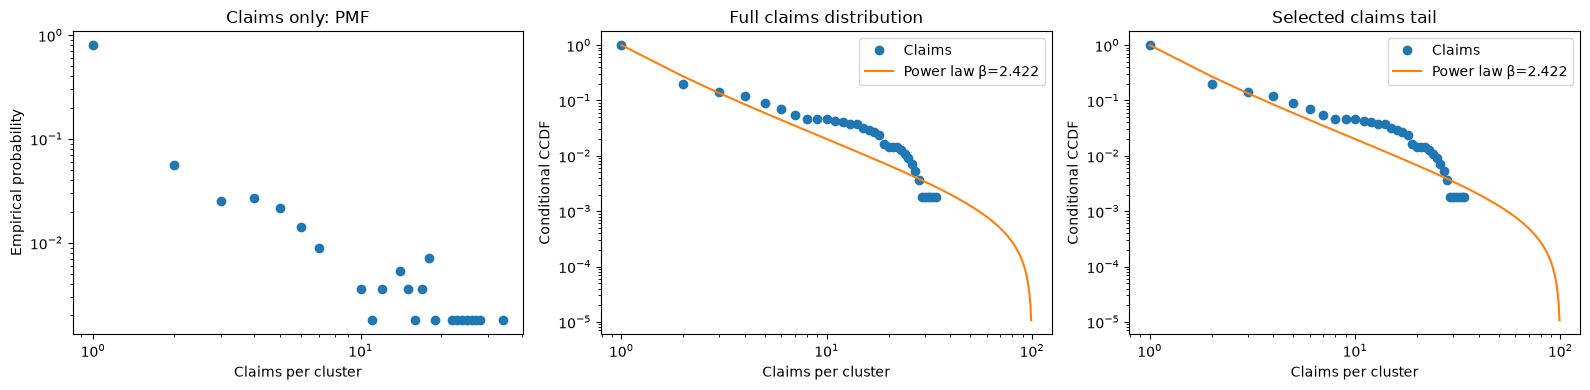

## Claims-only findings

**1,231 source claims form 558 claim clusters**, including 447 singletons (80.1%). There are 0 mixed claim/premise clusters in the original partition.

- **full claims distribution**: Reject at 0.05; p=0.002, beta=2.422, approximate 95% interval [2.279, 2.604], xmin=1, n=558 (100.0% of claim clusters).
- **claims tail; cutoff reselected**: Reject at 0.05; p=0.002, beta=2.422, approximate 95% interval [1.637, 2.599], xmin=1, n=558 (100.0% of claim clusters).

**The claims-only cluster-size data do not support the tested power-law models, including the automatically selected tail.** The exponents are estimates of rejected models, not parameters of an established law.

Observed maximum claim-cluster size: 34; structural cap: 99. The tail test repeats cutoff selection. Bootstrap inference approximates clusters as independent and is conditional on the existing partition; IsoRank was not rerun.

In [16]:
fig, axes=plt.subplots(1,3,figsize=(16,4))
positive=claim_counts>0
axes[0].loglog(claim_grid[positive],claim_empirical.probability[positive],'o')
axes[0].set(xlabel='Claims per cluster',ylabel='Empirical probability',title='Claims only: PMF')
for ax,fit,title in zip(axes[1:],[claim_full,claim_tail],['Full claims distribution','Selected claims tail']):
    grid=np.arange(fit['xmin'],CLAIM_UPPER+1)
    observed=claim_sizes[claim_sizes>=fit['xmin']]
    freq=np.bincount(observed-fit['xmin'],minlength=len(grid))/len(observed)
    ccdf=np.cumsum(freq[::-1])[::-1]
    ax.loglog(grid[ccdf>0],ccdf[ccdf>0],'o',label='Claims')
    ax.loglog(grid,np.cumsum(fit['prob'][::-1])[::-1],label=f"Power law β={fit['beta']:.3f}")
    ax.set(xlabel='Claims per cluster',ylabel='Conditional CCDF',title=title);ax.legend()
fig.tight_layout();fig.savefig(claim_out/'claims_power_law_fits.png',dpi=180);plt.show()
claim_lines=['## Claims-only findings','',
 f"**{len(claim_members):,} source claims form {len(claim_sizes):,} claim clusters**, including "
 f"{(claim_sizes==1).sum()} singletons ({(claim_sizes==1).mean():.1%}). "
 f"There are {claim_mixed_count} mixed claim/premise clusters in the original partition.",'']
for row in claim_results_rows:
    claim_lines.append(f"- **{row['range']}**: {row['decision']} at 0.05; p={row['bootstrap_p']:.3f}, "
       f"beta={row['beta']:.3f}, approximate 95% interval [{row['beta_CI_low']:.3f}, {row['beta_CI_high']:.3f}], "
       f"xmin={row['xmin']}, n={row['n']} ({row['tail_fraction']:.1%} of claim clusters).")
if (claim_results.bootstrap_p<CLAIM_SIGNIFICANCE).all():
    claim_lines += ['', '**The claims-only cluster-size data do not support the tested power-law models, including the automatically selected tail.** '
                    'The exponents are estimates of rejected models, not parameters of an established law.']
else:
    claim_lines += ['', 'Non-rejection means compatibility with a fitted model over its stated range; it does not prove a power law or show that power law beats alternative distributions.']
claim_lines += ['', f"Observed maximum claim-cluster size: {claim_sizes.max()}; structural cap: {CLAIM_UPPER}. "
                'The tail test repeats cutoff selection. Bootstrap inference approximates clusters as independent and is conditional on the existing partition; IsoRank was not rerun.']
claim_summary='\n'.join(claim_lines)
display(Markdown(claim_summary))
(claim_out/'claims_power_law_findings.md').write_text(claim_summary)
(claim_out/'claims_analysis_manifest.json').write_text(json.dumps({
    'filter': 'source member argument_type == CLAIM; count per existing cluster; omit zero-claim clusters',
    'seed':CLAIM_SEED,'bootstrap_replicates':CLAIM_B,'significance_threshold':CLAIM_SIGNIFICANCE,
    'minimum_tail_count':CLAIM_MIN_TAIL,'minimum_tail_distinct_sizes':5,
    'upper_bound':CLAIM_UPPER,'partition_sha256':claim_manifest['partition_sha256'],
    'input_sha256':{name:hashlib.sha256((claim_data/name).read_bytes()).hexdigest()
                    for name in ['manifest.json','global_members.parquet','global_nodes.parquet']},
    'tail_beta_fixed_cutoff_CI':claim_fixed_ci.tolist()},indent=2))


**Interpretation of this run:** the selected cutoff is `xmin=1`, so the “selected tail” contains the full claims sample. Its bootstrap test accounts for searching over cutoffs; it is not evidence about a distinct high-size tail. The eligible cutoffs were 1–5 (minimum 50 observations and 5 distinct sizes). This analysis does not rule out every possible smaller tail, nor establish the distribution after rebuilding IsoRank with claims only.

## Lognormal check: whole dataset versus premises only

Compare **all original arguments per cluster** with **original PREMISE arguments per premise-bearing cluster**, including singletons in both samples. Counts come from source-member labels, not representative labels. This preserves the existing IsoRank partition; it does not recluster a premises-only graph.

Use the same rounded continuous lognormal, conditioned on integer sizes $1\ldots99$, as the dedicated lognormal section above. Estimate latent $\mu,\sigma$ by maximum likelihood and test the discrete KS statistic using **499 parametric bootstrap replicates**, refitting parameters in every replicate. Reject at **p < 0.05**. The all-argument bootstrap result is reused only after checking input hashes and reproducing its point estimate. The premise bootstrap is newly computed with its own recorded seed.

A fitted parameter at its numerical bound is not a stable recovered parameter. Refit such models with a wider mu bound as a sensitivity check. These are unadjusted tests under an approximate iid cluster model, conditional on the saved partition. Whole-dataset and premise samples overlap, so their p-values are not independent evidence.

In [17]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import logsumexp
from IPython.display import display, Markdown

comparison_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src/legal_data_doc_parts').is_dir())
comparison_here = comparison_root/'src/legal_data_doc_parts/paragraph_analysis'
comparison_data = comparison_here/'structural_global_graph_artifacts'
comparison_out = comparison_here/'argument_distribution_artifacts'
comparison_manifest = json.loads((comparison_data/'manifest.json').read_text())
comparison_members = pd.read_parquet(comparison_data/'global_members.parquet')
comparison_nodes = pd.read_parquet(comparison_data/'global_nodes.parquet')
UPPER = len(comparison_manifest['document_ids'])
assert comparison_manifest['partition_config']['one_node_per_graph']
assert comparison_members.node_id.is_unique
assert not comparison_members.duplicated(['cluster_id','document_id']).any()
all_counts = comparison_members.groupby('global_node_id').size()
premise_members = comparison_members.loc[comparison_members.argument_type.eq('PREMISE')]
premise_counts = premise_members.groupby('global_node_id').size()
assert all_counts.sort_index().equals(comparison_nodes.member_count.sort_index())
assert premise_counts.sum() == len(premise_members)
comparison_samples = {'All arguments':all_counts.to_numpy(dtype=int), 'Premises only':premise_counts.to_numpy(dtype=int)}
for sample in comparison_samples.values(): assert np.all((sample>=1)&(sample<=UPPER))
premise_counts.rename('premise_count').to_csv(comparison_out/'premises_cluster_sizes.csv')
COMPARISON_B, COMPARISON_SEED, COMPARISON_ALPHA = 499, 20261108, 0.05
comparison_rng = np.random.default_rng(COMPARISON_SEED)
# Check that the cached whole-dataset bootstrap refers to these exact inputs.
original_analysis = json.loads((comparison_out/'analysis_manifest.json').read_text())
original_lognormal = json.loads((comparison_out/'rounded_lognormal_manifest.json').read_text())
for name in ['manifest.json','global_members.parquet','global_nodes.parquet']:
    assert hashlib.sha256((comparison_data/name).read_bytes()).hexdigest() == original_analysis['input_sha256'][name]
assert original_lognormal['partition_sha256'] == comparison_manifest['partition_sha256']
assert original_lognormal['bootstrap_replicates'] == COMPARISON_B
cached_whole = pd.read_csv(comparison_out/'rounded_lognormal_results.csv').set_index('lower').loc[1]

from scipy.special import log_ndtr

# Stable interval probabilities, including far normal tails.
def rounded_lognormal_logpmf(theta, lower, mu_bound=50):
    mu, log_sigma = theta
    grid = np.arange(lower, UPPER + 1)
    a = (np.log(grid - 0.5) - mu) / np.exp(log_sigma)
    b = (np.log(grid + 0.5) - mu) / np.exp(log_sigma)
    right = a > 0
    big = np.where(right, log_ndtr(-a), log_ndtr(b))
    small = np.where(right, log_ndtr(-b), log_ndtr(a))
    log_mass = big + np.log(-np.expm1(small - big))
    return log_mass - logsumexp(log_mass)

def fit_rounded_lognormal(x, lower=1, mu_bound=50):
    x = np.asarray(x, dtype=int); x = x[x >= lower]
    freq = np.bincount(x-lower, minlength=UPPER-lower+1)
    def loss(theta): return -float(freq @ rounded_lognormal_logpmf(theta, lower))
    bounds = [(-mu_bound, mu_bound), (-4, 4)]
    attempts = [minimize(loss, start, method='L-BFGS-B', bounds=bounds)
                for start in [(np.log(x).mean(), 0), (-5, 1), (-20, 2)]]
    converged = [r for r in attempts if r.success and np.isfinite(r.fun)]
    if not converged: raise RuntimeError('Lognormal optimization failed')
    best = min(converged, key=lambda r: r.fun)
    prob = np.exp(rounded_lognormal_logpmf(best.x, lower))
    assert np.isclose(prob.sum(), 1) and np.all(prob > 0)
    return dict(lower=lower, n=len(x), mu=float(best.x[0]), sigma=float(np.exp(best.x[1])),
                KS=float(np.max(np.abs(np.cumsum(freq)/len(x)-np.cumsum(prob)))),
                AIC=float(4+2*best.fun), prob=prob,
                boundary=any(min(abs(t-lo), abs(t-hi)) < 0.01 for t,(lo,hi) in zip(best.x,bounds)))



comparison_fits = {name:fit_rounded_lognormal(sample,1) for name,sample in comparison_samples.items()}
for field in ['mu','sigma','KS','AIC','n']:
    assert np.isclose(comparison_fits['All arguments'][field],cached_whole[field],rtol=1e-6,atol=1e-6)
premise_fit = comparison_fits['Premises only']
premise_boot_rows = []
for replicate in range(COMPARISON_B):
    sample = comparison_rng.choice(np.arange(1,UPPER+1),premise_fit['n'],p=premise_fit['prob'])
    refit = fit_rounded_lognormal(sample,1)
    premise_boot_rows.append({'replicate':replicate, **{k:v for k,v in refit.items() if k!='prob'}})
premise_boot = pd.DataFrame(premise_boot_rows)
premise_p = (1+int((premise_boot.KS>=premise_fit['KS']).sum()))/(COMPARISON_B+1)
premise_boot.to_csv(comparison_out/'premises_lognormal_bootstrap.csv',index=False)
comparison_rows = []
for name,fit in comparison_fits.items():
    sample = comparison_samples[name]
    p_value = float(cached_whole.bootstrap_p) if name=='All arguments' else premise_p
    comparison_rows.append({'sample':name,'source_arguments':int(sample.sum()),'clusters':len(sample),
        'singletons':int((sample==1).sum()),'singleton_fraction':float((sample==1).mean()),
        **{k:v for k,v in fit.items() if k!='prob'},'bootstrap_p':p_value,
        'MC_standard_error':float(np.sqrt(p_value*(1-p_value)/(COMPARISON_B+1))),
        'significance_threshold':COMPARISON_ALPHA,
        'decision':'Reject' if p_value<COMPARISON_ALPHA else 'Do not reject; not proven',
        'bootstrap_source':'reused, input hashes verified' if name=='All arguments' else 'new computation'})
comparison_results = pd.DataFrame(comparison_rows)
display(comparison_results)
comparison_results.to_csv(comparison_out/'all_vs_premises_lognormal_results.csv',index=False)
comparison_sensitivity=[]
for name,fit in comparison_fits.items():
    if fit['boundary']:
        wider=fit_rounded_lognormal(comparison_samples[name],1,mu_bound=200)
        comparison_sensitivity.append({'sample':name, **{k:v for k,v in wider.items() if k!='prob'}})
if comparison_sensitivity:
    display(Markdown('**Boundary sensitivity:** wider mu bounds (±200); p-values above refer to the original ±50 bounds.'))
    display(pd.DataFrame(comparison_sensitivity))
pd.DataFrame(comparison_sensitivity).to_csv(comparison_out/'all_vs_premises_lognormal_boundary_check.csv',index=False)


,sample,source_arguments,clusters,singletons,singleton_fraction,lower,n,mu,sigma,KS,AIC,boundary,bootstrap_p,MC_standard_error,significance_threshold,decision,bootstrap_source
0,All arguments,3941,1892,1501,0.793340,1,1892,-50.0,6.363837,0.045714,4005.831791,True,0.002,0.001998,0.05,Reject,"reused, input hashes verified"
1,Premises only,2710,1334,1054,0.790105,1,1334,-50.0,6.359660,0.042035,2819.347907,True,0.002,0.001998,0.05,Reject,new computation


**Boundary sensitivity:** wider mu bounds (±200); p-values above refer to the original ±50 bounds.

,sample,lower,n,mu,sigma,KS,AIC,boundary
0,All arguments,1,1892,-200.0,12.634405,0.043784,4001.940991,True
1,Premises only,1,1334,-200.0,12.627464,0.040175,2817.014545,True


Out[0]: 850


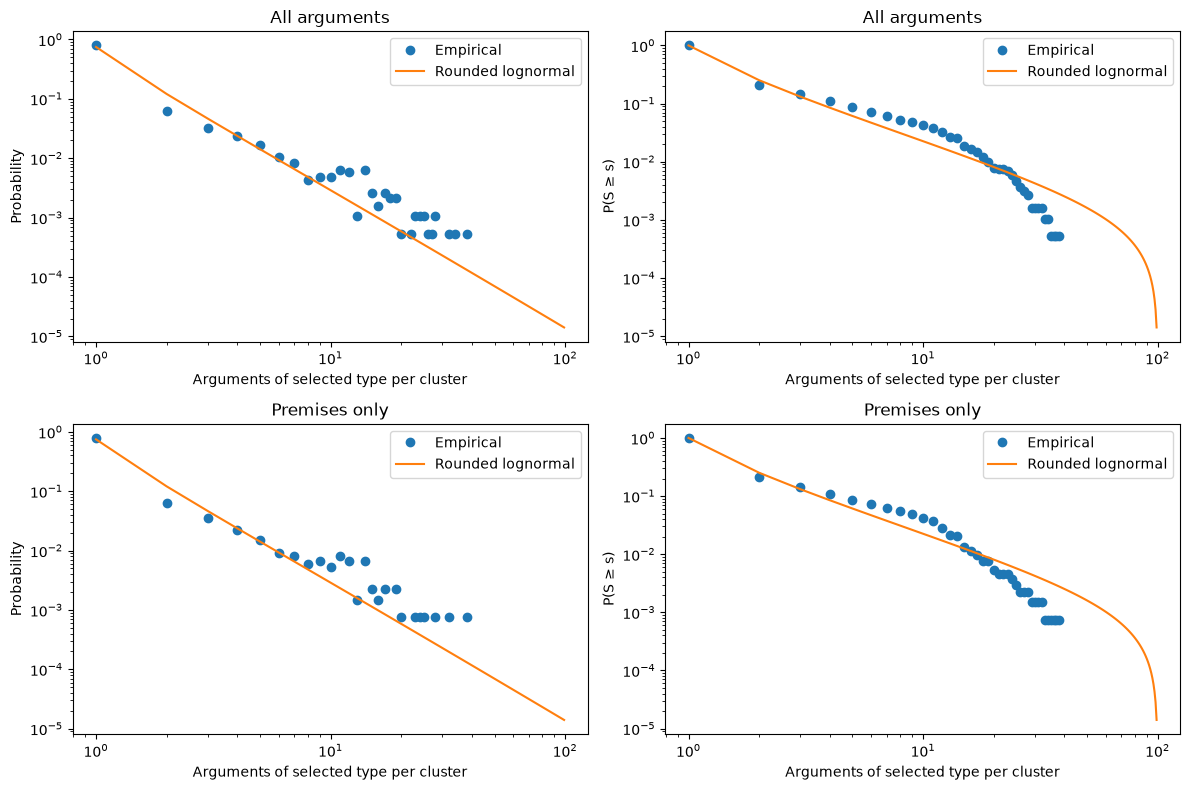

## Whole dataset and premises: lognormal findings

- **All arguments**: 3,941 arguments in 1,892 clusters; 79.3% singletons. **Reject** at 0.05: p=0.002. Fitted mu=-50.000, sigma=6.364. **Boundary fit: these parameters are unstable.**
- **Premises only**: 2,710 arguments in 1,334 clusters; 79.0% singletons. **Reject** at 0.05: p=0.002. Fitted mu=-50.000, sigma=6.360. **Boundary fit: these parameters are unstable.**

**Neither the whole cluster-size distribution nor the premises-only cluster-size distribution supports the tested rounded-lognormal model.**

All clusters, including singletons, are retained in each relevant sample. The whole-data bootstrap is reused after input-hash and fitted-parameter verification. Premise inference is newly bootstrapped. These conclusions apply to the existing partition and the specified finite-support model, under an approximate independence assumption. No premises-only tail search or reclustering is performed.

In [18]:
fig, axes=plt.subplots(2,2,figsize=(12,8))
comparison_empirical=[]
for row,(name,sample) in enumerate(comparison_samples.items()):
    grid=np.arange(1,UPPER+1)
    counts=np.bincount(sample,minlength=UPPER+1)[1:]
    pmf=counts/len(sample);ccdf=np.cumsum(pmf[::-1])[::-1]
    comparison_empirical.append(pd.DataFrame({'sample':name,'size':grid,'count':counts,'probability':pmf,'ccdf':ccdf}))
    fit=comparison_fits[name]
    axes[row,0].loglog(grid[counts>0],pmf[counts>0],'o',label='Empirical')
    axes[row,0].loglog(grid,fit['prob'],label='Rounded lognormal')
    axes[row,1].loglog(grid[ccdf>0],ccdf[ccdf>0],'o',label='Empirical')
    axes[row,1].loglog(grid,np.cumsum(fit['prob'][::-1])[::-1],label='Rounded lognormal')
    for ax,ylabel in zip(axes[row],['Probability','P(S ≥ s)']):
        ax.set(title=name,xlabel='Arguments of selected type per cluster',ylabel=ylabel);ax.legend()
fig.tight_layout();fig.savefig(comparison_out/'all_vs_premises_lognormal_fits.png',dpi=180);plt.show()
pd.concat(comparison_empirical,ignore_index=True).to_csv(comparison_out/'all_vs_premises_distributions.csv',index=False)
comparison_lines=['## Whole dataset and premises: lognormal findings','']
for row in comparison_rows:
    comparison_lines.append(f"- **{row['sample']}**: {row['source_arguments']:,} arguments in {row['clusters']:,} clusters; "
        f"{row['singleton_fraction']:.1%} singletons. **{row['decision']}** at 0.05: p={row['bootstrap_p']:.3f}. "
        f"Fitted mu={row['mu']:.3f}, sigma={row['sigma']:.3f}. "
        + ('**Boundary fit: these parameters are unstable.**' if row['boundary'] else ''))
if all(row['bootstrap_p']<COMPARISON_ALPHA for row in comparison_rows):
    comparison_lines += ['', '**Neither the whole cluster-size distribution nor the premises-only cluster-size distribution supports the tested rounded-lognormal model.**']
comparison_lines += ['', 'All clusters, including singletons, are retained in each relevant sample. '
    'The whole-data bootstrap is reused after input-hash and fitted-parameter verification. '
    'Premise inference is newly bootstrapped. These conclusions apply to the existing partition and '
    'the specified finite-support model, under an approximate independence assumption. '
    'No premises-only tail search or reclustering is performed.']
comparison_summary='\n'.join(comparison_lines)
display(Markdown(comparison_summary))
(comparison_out/'all_vs_premises_lognormal_findings.md').write_text(comparison_summary)
(comparison_out/'all_vs_premises_lognormal_manifest.json').write_text(json.dumps({
    'premise_seed':COMPARISON_SEED,'whole_data_seed':original_lognormal['seed'],
    'bootstrap_replicates':COMPARISON_B,'significance_threshold':COMPARISON_ALPHA,
    'model':'rounded continuous lognormal, conditioned on integer sizes 1..document_count',
    'mu_bounds':[-50,50],'log_sigma_bounds':[-4,4],'sensitivity_mu_bounds':[-200,200],
    'filter':'source argument_type == PREMISE; count per existing cluster; omit zero-premise clusters',
    'partition_sha256':comparison_manifest['partition_sha256'],
    'input_sha256':{name:hashlib.sha256((comparison_data/name).read_bytes()).hexdigest()
                    for name in ['manifest.json','global_members.parquet','global_nodes.parquet']}
},indent=2))


## Lognormal comparison including claims

Filter source members to `CLAIM`, count them per existing cluster, and retain all nonempty claim clusters, including singletons. Test the same rounded-lognormal model on sizes 1 through the document-count cap, using 499 refitted parametric bootstrap replicates and significance **0.05**. Whole-data and premise results are reused only after verifying their input hashes and reproducing their fitted parameters. This analysis does not recluster or search for a claims-only lognormal tail. The iid-cluster approximation and parameter-bound caveats above still apply.

In [19]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import logsumexp
from IPython.display import display, Markdown

comparison_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src/legal_data_doc_parts').is_dir())
comparison_here = comparison_root/'src/legal_data_doc_parts/paragraph_analysis'
comparison_data = comparison_here/'structural_global_graph_artifacts'
comparison_out = comparison_here/'argument_distribution_artifacts'
comparison_manifest = json.loads((comparison_data/'manifest.json').read_text())
comparison_members = pd.read_parquet(comparison_data/'global_members.parquet')
comparison_nodes = pd.read_parquet(comparison_data/'global_nodes.parquet')
UPPER = len(comparison_manifest['document_ids'])
assert comparison_manifest['partition_config']['one_node_per_graph']
assert comparison_members.node_id.is_unique
assert not comparison_members.duplicated(['cluster_id','document_id']).any()
all_counts = comparison_members.groupby('global_node_id').size()
premise_members = comparison_members.loc[comparison_members.argument_type.eq('PREMISE')]
premise_counts = premise_members.groupby('global_node_id').size()
assert all_counts.sort_index().equals(comparison_nodes.member_count.sort_index())
assert premise_counts.sum() == len(premise_members)
comparison_samples = {'All arguments':all_counts.to_numpy(dtype=int), 'Premises only':premise_counts.to_numpy(dtype=int)}
for sample in comparison_samples.values(): assert np.all((sample>=1)&(sample<=UPPER))
premise_counts.rename('premise_count').to_csv(comparison_out/'premises_cluster_sizes.csv')
COMPARISON_B, COMPARISON_SEED, COMPARISON_ALPHA = 499, 20261108, 0.05
comparison_rng = np.random.default_rng(COMPARISON_SEED)
# Check that the cached whole-dataset bootstrap refers to these exact inputs.
original_analysis = json.loads((comparison_out/'analysis_manifest.json').read_text())
original_lognormal = json.loads((comparison_out/'rounded_lognormal_manifest.json').read_text())
for name in ['manifest.json','global_members.parquet','global_nodes.parquet']:
    assert hashlib.sha256((comparison_data/name).read_bytes()).hexdigest() == original_analysis['input_sha256'][name]
assert original_lognormal['partition_sha256'] == comparison_manifest['partition_sha256']
assert original_lognormal['bootstrap_replicates'] == COMPARISON_B
cached_whole = pd.read_csv(comparison_out/'rounded_lognormal_results.csv').set_index('lower').loc[1]

from scipy.special import log_ndtr

# Stable interval probabilities, including far normal tails.
def rounded_lognormal_logpmf(theta, lower, mu_bound=50):
    mu, log_sigma = theta
    grid = np.arange(lower, UPPER + 1)
    a = (np.log(grid - 0.5) - mu) / np.exp(log_sigma)
    b = (np.log(grid + 0.5) - mu) / np.exp(log_sigma)
    right = a > 0
    big = np.where(right, log_ndtr(-a), log_ndtr(b))
    small = np.where(right, log_ndtr(-b), log_ndtr(a))
    log_mass = big + np.log(-np.expm1(small - big))
    return log_mass - logsumexp(log_mass)

def fit_rounded_lognormal(x, lower=1, mu_bound=50):
    x = np.asarray(x, dtype=int); x = x[x >= lower]
    freq = np.bincount(x-lower, minlength=UPPER-lower+1)
    def loss(theta): return -float(freq @ rounded_lognormal_logpmf(theta, lower))
    bounds = [(-mu_bound, mu_bound), (-4, 4)]
    attempts = [minimize(loss, start, method='L-BFGS-B', bounds=bounds)
                for start in [(np.log(x).mean(), 0), (-5, 1), (-20, 2)]]
    converged = [r for r in attempts if r.success and np.isfinite(r.fun)]
    if not converged: raise RuntimeError('Lognormal optimization failed')
    best = min(converged, key=lambda r: r.fun)
    prob = np.exp(rounded_lognormal_logpmf(best.x, lower))
    assert np.isclose(prob.sum(), 1) and np.all(prob > 0)
    return dict(lower=lower, n=len(x), mu=float(best.x[0]), sigma=float(np.exp(best.x[1])),
                KS=float(np.max(np.abs(np.cumsum(freq)/len(x)-np.cumsum(prob)))),
                AIC=float(4+2*best.fun), prob=prob,
                boundary=any(min(abs(t-lo), abs(t-hi)) < 0.01 for t,(lo,hi) in zip(best.x,bounds)))




claims_ln_members = comparison_members.loc[comparison_members.argument_type.eq('CLAIM')]
claims_ln_counts = claims_ln_members.groupby('global_node_id').size()
assert claims_ln_counts.sum() == len(claims_ln_members)
comparison_samples['Claims only'] = claims_ln_counts.to_numpy(dtype=int)
comparison_fits = {name:fit_rounded_lognormal(sample,1) for name,sample in comparison_samples.items()}
prior_premise_manifest=json.loads((comparison_out/'all_vs_premises_lognormal_manifest.json').read_text())
for name,digest in prior_premise_manifest['input_sha256'].items():
    assert hashlib.sha256((comparison_data/name).read_bytes()).hexdigest()==digest
assert prior_premise_manifest['bootstrap_replicates']==COMPARISON_B
prior_results=pd.read_csv(comparison_out/'all_vs_premises_lognormal_results.csv').set_index('sample')
for name in ['All arguments','Premises only']:
    for field in ['mu','sigma','KS','AIC','n']:
        assert np.isclose(comparison_fits[name][field],prior_results.loc[name,field],rtol=1e-6,atol=1e-6)
CLAIMS_LN_SEED=20261109
claims_ln_rng=np.random.default_rng(CLAIMS_LN_SEED)
claims_ln_fit=comparison_fits['Claims only']
claims_ln_boot_rows=[]
for replicate in range(COMPARISON_B):
    sample=claims_ln_rng.choice(np.arange(1,UPPER+1),claims_ln_fit['n'],p=claims_ln_fit['prob'])
    refit=fit_rounded_lognormal(sample,1)
    claims_ln_boot_rows.append({'replicate':replicate,**{k:v for k,v in refit.items() if k!='prob'}})
claims_ln_boot=pd.DataFrame(claims_ln_boot_rows)
claims_ln_p=(1+int((claims_ln_boot.KS>=claims_ln_fit['KS']).sum()))/(COMPARISON_B+1)
claims_ln_boot.to_csv(comparison_out/'claims_lognormal_bootstrap.csv',index=False)
comparison_rows=[]
for name,fit in comparison_fits.items():
    sample=comparison_samples[name]
    p_value=claims_ln_p if name=='Claims only' else float(prior_results.loc[name,'bootstrap_p'])
    comparison_rows.append({'sample':name,'source_arguments':int(sample.sum()),'clusters':len(sample),
        'singletons':int((sample==1).sum()),'singleton_fraction':float((sample==1).mean()),
        **{k:v for k,v in fit.items() if k!='prob'},'bootstrap_p':p_value,
        'MC_standard_error':float(np.sqrt(p_value*(1-p_value)/(COMPARISON_B+1))),
        'significance_threshold':COMPARISON_ALPHA,
        'decision':'Reject' if p_value<COMPARISON_ALPHA else 'Do not reject; not proven',
        'bootstrap_source':'new computation' if name=='Claims only' else 'reused, inputs verified'})
comparison_results=pd.DataFrame(comparison_rows)
display(comparison_results)
comparison_results.to_csv(comparison_out/'all_types_lognormal_results.csv',index=False)
if claims_ln_fit['boundary']:
    claims_ln_wider=fit_rounded_lognormal(comparison_samples['Claims only'],1,mu_bound=200)
    display(Markdown('**Claims parameter-bound sensitivity:** mu bounds widened to ±200. Bootstrap p-value refers to the original ±50 bound.'))
    display(pd.DataFrame([{k:v for k,v in claims_ln_wider.items() if k!='prob'}]))
    (comparison_out/'claims_lognormal_boundary_check.json').write_text(json.dumps(
        {k:v for k,v in claims_ln_wider.items() if k!='prob'},indent=2))


,sample,source_arguments,clusters,singletons,singleton_fraction,lower,n,mu,sigma,KS,AIC,boundary,bootstrap_p,MC_standard_error,significance_threshold,decision,bootstrap_source
0,All arguments,3941,1892,1501,0.793340,1,1892,-50.0,6.363837,0.045714,4005.831791,True,0.002,0.001998,0.05,Reject,"reused, inputs verified"
1,Premises only,2710,1334,1054,0.790105,1,1334,-50.0,6.359660,0.042035,2819.347907,True,0.002,0.001998,0.05,Reject,"reused, inputs verified"
2,Claims only,1231,558,447,0.801075,1,558,-50.0,6.373828,0.054509,1190.477572,True,0.002,0.001998,0.05,Reject,new computation


**Claims parameter-bound sensitivity:** mu bounds widened to ±200. Bootstrap p-value refers to the original ±50 bound.

,lower,n,mu,sigma,KS,AIC,boundary
0,1,558,-200.0,12.651008,0.052412,1188.921963,True


Out[0]: 894


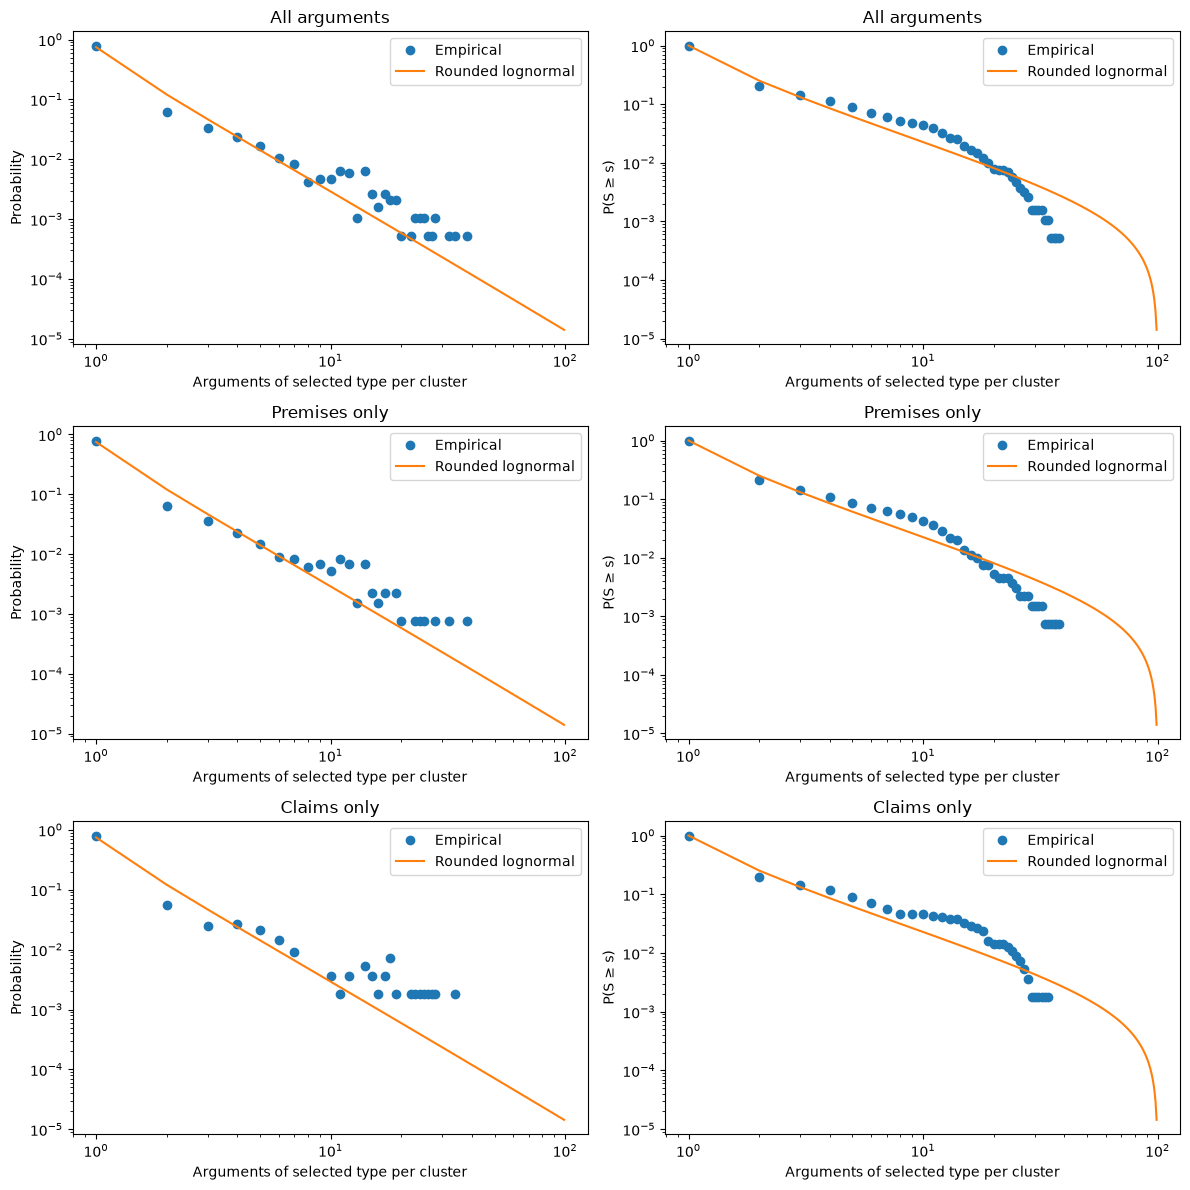

## Whole dataset, premises, and claims: lognormal findings

- **All arguments**: 3,941 arguments in 1,892 clusters; 79.3% singletons. **Reject** at 0.05: p=0.002. Fitted mu=-50.000, sigma=6.364. **Boundary fit: these parameters are unstable.**
- **Premises only**: 2,710 arguments in 1,334 clusters; 79.0% singletons. **Reject** at 0.05: p=0.002. Fitted mu=-50.000, sigma=6.360. **Boundary fit: these parameters are unstable.**
- **Claims only**: 1,231 arguments in 558 clusters; 80.1% singletons. **Reject** at 0.05: p=0.002. Fitted mu=-50.000, sigma=6.374. **Boundary fit: these parameters are unstable.**

**None of the three full cluster-size distributions supports the tested rounded-lognormal model.**

All clusters, including singletons, are retained in each relevant sample. The whole-data and premise bootstraps are reused after input-hash and fitted-parameter verification. Claims inference is newly bootstrapped. These conclusions apply to the existing partition and the specified finite-support model, under an approximate independence assumption. No new tail search or reclustering is performed.

In [20]:
fig, axes=plt.subplots(3,2,figsize=(12,12))
comparison_empirical=[]
for row,(name,sample) in enumerate(comparison_samples.items()):
    grid=np.arange(1,UPPER+1)
    counts=np.bincount(sample,minlength=UPPER+1)[1:]
    pmf=counts/len(sample);ccdf=np.cumsum(pmf[::-1])[::-1]
    comparison_empirical.append(pd.DataFrame({'sample':name,'size':grid,'count':counts,'probability':pmf,'ccdf':ccdf}))
    fit=comparison_fits[name]
    axes[row,0].loglog(grid[counts>0],pmf[counts>0],'o',label='Empirical')
    axes[row,0].loglog(grid,fit['prob'],label='Rounded lognormal')
    axes[row,1].loglog(grid[ccdf>0],ccdf[ccdf>0],'o',label='Empirical')
    axes[row,1].loglog(grid,np.cumsum(fit['prob'][::-1])[::-1],label='Rounded lognormal')
    for ax,ylabel in zip(axes[row],['Probability','P(S ≥ s)']):
        ax.set(title=name,xlabel='Arguments of selected type per cluster',ylabel=ylabel);ax.legend()
fig.tight_layout();fig.savefig(comparison_out/'all_types_lognormal_fits.png',dpi=180);plt.show()
pd.concat(comparison_empirical,ignore_index=True).to_csv(comparison_out/'all_types_distributions.csv',index=False)
comparison_lines=['## Whole dataset, premises, and claims: lognormal findings','']
for row in comparison_rows:
    comparison_lines.append(f"- **{row['sample']}**: {row['source_arguments']:,} arguments in {row['clusters']:,} clusters; "
        f"{row['singleton_fraction']:.1%} singletons. **{row['decision']}** at 0.05: p={row['bootstrap_p']:.3f}. "
        f"Fitted mu={row['mu']:.3f}, sigma={row['sigma']:.3f}. "
        + ('**Boundary fit: these parameters are unstable.**' if row['boundary'] else ''))
if all(row['bootstrap_p']<COMPARISON_ALPHA for row in comparison_rows):
    comparison_lines += ['', '**None of the three full cluster-size distributions supports the tested rounded-lognormal model.**']
comparison_lines += ['', 'All clusters, including singletons, are retained in each relevant sample. '
    'The whole-data and premise bootstraps are reused after input-hash and fitted-parameter verification. '
    'Claims inference is newly bootstrapped. These conclusions apply to the existing partition and '
    'the specified finite-support model, under an approximate independence assumption. '
    'No new tail search or reclustering is performed.']
comparison_summary='\n'.join(comparison_lines)
display(Markdown(comparison_summary))
(comparison_out/'all_types_lognormal_findings.md').write_text(comparison_summary)
(comparison_out/'all_types_lognormal_manifest.json').write_text(json.dumps({
    'claims_seed':CLAIMS_LN_SEED,'premise_seed':COMPARISON_SEED,'whole_data_seed':original_lognormal['seed'],
    'bootstrap_replicates':COMPARISON_B,'significance_threshold':COMPARISON_ALPHA,
    'model':'rounded continuous lognormal, conditioned on integer sizes 1..document_count',
    'mu_bounds':[-50,50],'log_sigma_bounds':[-4,4],'sensitivity_mu_bounds':[-200,200],
    'filter':'count source members per existing cluster for all arguments, PREMISE, and CLAIM; omit zero-type clusters',
    'partition_sha256':comparison_manifest['partition_sha256'],
    'input_sha256':{name:hashlib.sha256((comparison_data/name).read_bytes()).hexdigest()
                    for name in ['manifest.json','global_members.parquet','global_nodes.parquet']}
},indent=2))


## Claims power law: exclude singleton clusters and refit the orange curve

Use claim counts within the existing partition, retaining only clusters with **at least two claims**. Renormalize the empirical PMF and CCDF on that subset: $P(S=s\mid S\ge2)$ and $P(S\ge s\mid S\ge2)$. This is not the original distribution with its first point hidden.

The **orange curve** directly fits the empirical CCDF on logarithmic axes by minimizing the mean squared log-CCDF residual over every integer from 2 through the observed maximum. Its probabilities still come from the normalized finite discrete power law
$$p_\beta(s)=s^{-\beta}/\sum_{j=2}^{99}j^{-\beta},\quad s=2,\ldots,99.$$
There is no free vertical offset or fitted upper bound. The known structural cap remains 99, not the observed maximum. A dashed gray curve shows the maximum-likelihood fit to the raw counts as a statistical reference.

Both methods estimate beta afresh on this subset. For each method, bootstrap goodness of fit uses 499 samples from its fitted distribution, refits with the **same objective**, and compares discrete KS distances. The CCDF fitting range is recomputed in every replicate. Correlated CCDF points are not treated as independent observations in a regression test. Nonparametric bootstrap provides approximate 95% beta intervals. Reject if **p < 0.05**. An improved visual fit alone does not establish a power law; iid cluster and fixed-partition caveats remain.

In [21]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.special import logsumexp
from IPython.display import display, Markdown

ns_root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/legal_data_doc_parts').is_dir())
ns_here=ns_root/'src/legal_data_doc_parts/paragraph_analysis'
ns_data=ns_here/'structural_global_graph_artifacts'
ns_out=ns_here/'argument_distribution_artifacts'
ns_manifest=json.loads((ns_data/'manifest.json').read_text())
ns_members=pd.read_parquet(ns_data/'global_members.parquet')
ns_claim_counts=ns_members.loc[ns_members.argument_type.eq('CLAIM')].groupby('global_node_id').size()
ns_retained=ns_claim_counts[ns_claim_counts>=2]
ns_sample=ns_retained.to_numpy(dtype=int)
NS_LOWER,NS_UPPER=2,len(ns_manifest['document_ids'])
NS_B,NS_SEED,NS_ALPHA=499,20261110,0.05
assert ns_manifest['partition_config']['one_node_per_graph']
assert len(ns_sample)>0 and np.all((ns_sample>=NS_LOWER)&(ns_sample<=NS_UPPER))
ns_grid=np.arange(NS_LOWER,NS_UPPER+1)
ns_rng=np.random.default_rng(NS_SEED)
ns_retained.rename('claim_count').to_csv(ns_out/'claims_without_singletons_sizes.csv')

def ns_power_fit(sample,method):
    sample=np.asarray(sample,dtype=int)
    counts=np.bincount(sample-NS_LOWER,minlength=len(ns_grid))
    empirical_pmf=counts/len(sample)
    empirical_ccdf=np.cumsum(empirical_pmf[::-1])[::-1]
    positive=empirical_ccdf>0
    def log_prob(beta): return -beta*np.log(ns_grid)-logsumexp(-beta*np.log(ns_grid))
    def loss(beta):
        lp=log_prob(beta)
        if method=='MLE': return -float(counts@lp)
        log_ccdf=np.logaddexp.accumulate(lp[::-1])[::-1]
        return float(np.mean((log_ccdf[positive]-np.log(empirical_ccdf[positive]))**2))
    opt=minimize_scalar(loss,bounds=(0,30),method='bounded')
    assert opt.success
    prob=np.exp(log_prob(opt.x))
    assert np.isclose(prob.sum(),1)
    return {'method':method,'beta':float(opt.x),'prob':prob,
            'KS':float(np.max(np.abs(np.cumsum(empirical_pmf)-np.cumsum(prob)))),
            'log_CCDF_RMSE':float(np.sqrt(np.mean((np.log(np.cumsum(prob[::-1])[::-1][positive])-np.log(empirical_ccdf[positive]))**2))),
            'boundary':bool(min(opt.x,30-opt.x)<.01)}

ns_fits={method:ns_power_fit(ns_sample,method) for method in ['CCDF curve fit','MLE']}
ns_boot_rows=[]
for method,fit in ns_fits.items():
    for replicate in range(NS_B):
        simulated=ns_rng.choice(ns_grid,len(ns_sample),p=fit['prob'])
        refit=ns_power_fit(simulated,method)
        empirical_refit=ns_power_fit(ns_rng.choice(ns_sample,len(ns_sample),replace=True),method)
        ns_boot_rows.append({'method':method,'replicate':replicate,'null_KS':refit['KS'],
                            'resampled_beta':empirical_refit['beta']})
ns_boot=pd.DataFrame(ns_boot_rows)
ns_rows=[]
for method,fit in ns_fits.items():
    replicates=ns_boot.loc[ns_boot.method.eq(method)]
    exceedances=int((replicates.null_KS>=fit['KS']).sum())
    p_value=(1+exceedances)/(NS_B+1)
    interval=replicates.resampled_beta.quantile([.025,.975]).to_numpy()
    ns_rows.append({k:v for k,v in fit.items() if k!='prob'} | {
        'clusters':len(ns_sample),'xmin':NS_LOWER,'upper_bound':NS_UPPER,
        'bootstrap_p':p_value,'null_exceedances':exceedances,
        'MC_standard_error':np.sqrt(p_value*(1-p_value)/(NS_B+1)),
        'beta_CI_low':interval[0],'beta_CI_high':interval[1],
        'decision':'Reject' if p_value<NS_ALPHA else 'Do not reject; not proven'})
ns_results=pd.DataFrame(ns_rows)
display(pd.Series({'excluded_singleton_clusters':int((ns_claim_counts==1).sum()),
    'retained_claim_clusters':len(ns_sample),'retained_source_claims':int(ns_sample.sum()),
    'observed_minimum':int(ns_sample.min()),'observed_maximum':int(ns_sample.max())},name='value').to_frame())
display(ns_results)
ns_results.to_csv(ns_out/'claims_without_singletons_power_law_results.csv',index=False)
ns_boot.to_csv(ns_out/'claims_without_singletons_bootstrap.csv',index=False)


,value
excluded_singleton_clusters,447
retained_claim_clusters,111
retained_source_claims,784
observed_minimum,2
observed_maximum,34


,method,beta,KS,log_CCDF_RMSE,boundary,clusters,xmin,upper_bound,bootstrap_p,null_exceedances,MC_standard_error,beta_CI_low,beta_CI_high,decision
0,CCDF curve fit,2.087416,0.190993,0.655242,False,111,2,99,0.006,2,0.003454,1.784720,2.252699,Reject
1,MLE,1.759995,0.080359,0.917181,False,111,2,99,0.030,14,0.007629,1.606917,1.932981,Reject


Out[0]: 588


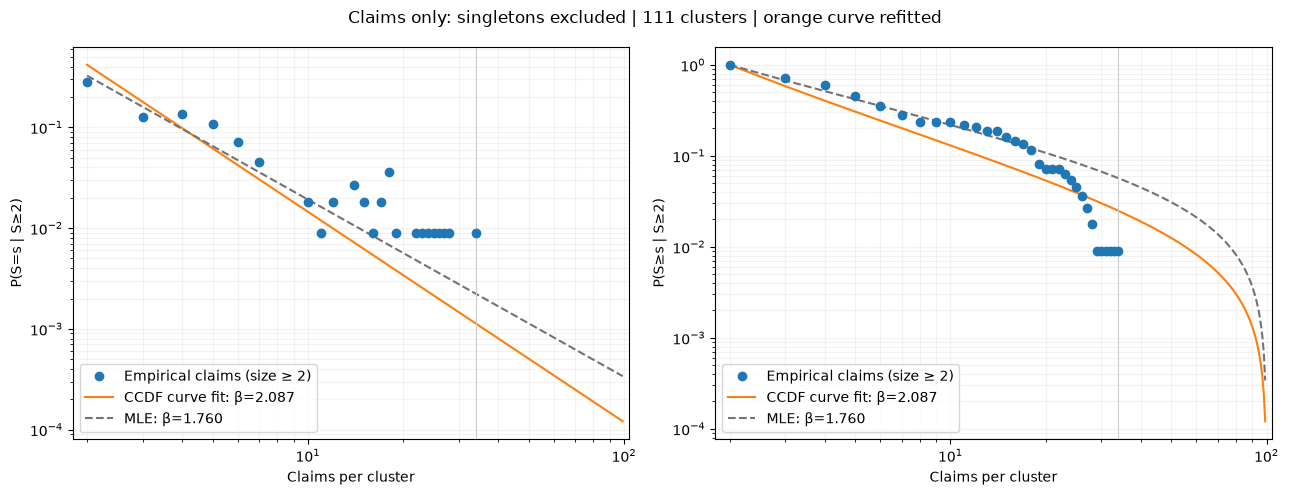

## Claims without singletons: fitted power-law curves

Excluded 447 singleton clusters. Retained **111 clusters containing 784 claims**, with observed sizes 2–34.

- **CCDF curve fit**: beta=2.087 (95% bootstrap interval [1.785, 2.253]); KS=0.191, p=0.006: **Reject** at 0.05.
- **MLE**: beta=1.760 (95% bootstrap interval [1.607, 1.933]); KS=0.080, p=0.030: **Reject** at 0.05.

The orange curve is optimized directly against the empirical log-CCDF; the dashed gray curve maximizes the raw-count likelihood. Both remain normalized discrete power laws on sizes 2–99. Removing singletons changes the sampled population, not merely the plotting limits.

**Excluding singletons still does not make this claims-cluster distribution compatible with the tested power law under either fitting method.**

In [22]:
ns_counts=np.bincount(ns_sample-NS_LOWER,minlength=len(ns_grid))
ns_pmf=ns_counts/len(ns_sample)
ns_ccdf=np.cumsum(ns_pmf[::-1])[::-1]
ns_empirical=pd.DataFrame({'size':ns_grid,'count':ns_counts,'conditional_probability':ns_pmf,'conditional_ccdf':ns_ccdf})
for method,fit in ns_fits.items():
    ns_empirical[method+'_pmf']=fit['prob']
    ns_empirical[method+'_ccdf']=np.cumsum(fit['prob'][::-1])[::-1]
assert np.isclose(ns_pmf.sum(),1) and np.isclose(ns_ccdf[0],1)
ns_empirical.to_csv(ns_out/'claims_without_singletons_fitted_curves.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(13,5))
axes[0].loglog(ns_grid[ns_counts>0],ns_pmf[ns_counts>0],'o',color='tab:blue',label='Empirical claims (size ≥ 2)',zorder=3)
axes[1].loglog(ns_grid[ns_ccdf>0],ns_ccdf[ns_ccdf>0],'o',color='tab:blue',label='Empirical claims (size ≥ 2)',zorder=3)
for method,fit in ns_fits.items():
    color,style=('tab:orange','-') if method=='CCDF curve fit' else ('0.45','--')
    label=f"{method}: β={fit['beta']:.3f}"
    axes[0].loglog(ns_grid,fit['prob'],color=color,linestyle=style,label=label)
    axes[1].loglog(ns_grid,np.cumsum(fit['prob'][::-1])[::-1],color=color,linestyle=style,label=label)
for ax,ylabel in zip(axes,['P(S=s | S≥2)','P(S≥s | S≥2)']):
    ax.set(xlabel='Claims per cluster',ylabel=ylabel,xlim=(1.8,NS_UPPER*1.05))
    ax.axvline(ns_sample.max(),color='0.8',linewidth=.8)
    ax.legend();ax.grid(alpha=.15,which='both')
fig.suptitle(f'Claims only: singletons excluded | {len(ns_sample)} clusters | orange curve refitted')
fig.tight_layout();fig.savefig(ns_out/'claims_without_singletons_power_law_fit.png',dpi=180)
fig.savefig(ns_out/'claims_without_singletons_power_law_fit.svg');plt.show()
ns_lines=['## Claims without singletons: fitted power-law curves','',
    f"Excluded {(ns_claim_counts==1).sum()} singleton clusters. Retained **{len(ns_sample)} clusters containing {ns_sample.sum()} claims**, with observed sizes {ns_sample.min()}–{ns_sample.max()}.",'']
for row in ns_rows:
    ns_lines.append(f"- **{row['method']}**: beta={row['beta']:.3f} (95% bootstrap interval "
        f"[{row['beta_CI_low']:.3f}, {row['beta_CI_high']:.3f}]); KS={row['KS']:.3f}, "
        f"p={row['bootstrap_p']:.3f}: **{row['decision']}** at 0.05.")
ns_lines += ['', 'The orange curve is optimized directly against the empirical log-CCDF; the dashed gray curve maximizes the raw-count likelihood. '
    'Both remain normalized discrete power laws on sizes 2–99. '
    'Removing singletons changes the sampled population, not merely the plotting limits.']
if all(row['bootstrap_p']<NS_ALPHA for row in ns_rows):
    ns_lines += ['', '**Excluding singletons still does not make this claims-cluster distribution compatible with the tested power law under either fitting method.**']
else:
    ns_lines += ['', 'Non-rejection is compatibility with this conditional model, not proof of a power law. No alternative-law comparison is made in this section.']
ns_summary='\n'.join(ns_lines)
display(Markdown(ns_summary))
(ns_out/'claims_without_singletons_findings.md').write_text(ns_summary)
(ns_out/'claims_without_singletons_manifest.json').write_text(json.dumps({
    'seed':NS_SEED,'bootstrap_replicates_per_method':NS_B,'significance_threshold':NS_ALPHA,
    'filter':'source CLAIM members counted within existing clusters, retaining claim count >=2',
    'methods':list(ns_fits),'lower_bound':NS_LOWER,'upper_bound':NS_UPPER,
    'partition_sha256':ns_manifest['partition_sha256'],
    'input_sha256':{name:hashlib.sha256((ns_data/name).read_bytes()).hexdigest()
                    for name in ['manifest.json','global_members.parquet']}
},indent=2))
